# Week 5 - DX 799 mod C3 Deb Halder 2026 Fall - Phishing Email Detection- Dataset-3 - Linear SVM, RBF and Polynomial

**Objective:** classify Safe (0) and Phishing (1) emails using linear, RBF, and
polynomial SVMs with TF-IDF plus six retained count features.

**Notebook Flow:**

1. **Sections 1–3 — Prepare data:** load Dataset 3 file from kaggle, remove blank text and duplicate text/label pairs, inspect email sizes, then clean and deduplicate emails, cap cleaned text at the 99th-percentile length, and retain six counts after dropping constant URL and sentence counts. Create a grouped 80/20 train/holdout split and three training CV folds.
2. **Section 4 — Create TF-IDF:** fit up to `MAX_FEATURES_TFIDF` unigram/bigram features on training text only; transform the holdout with the fitted vectorizer. NLTK stopwords protect feature keywords and negations.
3. **Sections 5–6 — Analyze counts:** use a full-corpus copy with log1p-transformed counts for univariate and bivariate analysis; TF-IDF is reserved for modeling. Though I have used 9 features in other cases but during initial analysis I see three of the features are same values for the whole dataset and the will use only 6 engineered features.
4. **Sections 7–8 — Prepare model inputs:** append the six raw counts to TF-IDF and check feature shapes, order, and label alignment.
5. **Sections 9–10 — Define SVM methods:** build, tune, and evaluate pipelines using `train_df` and `test_df`. Pipelines apply log1p and scaling to counts and fit preprocessing within each training fold.
6. **Section 11 — Establish baselines:** fit the three fixed-setting SVMs and evaluate their holdout performance.
7. **Section 12 — Tune and compare:** test 12 configurations using three-fold grouped CV, select by validation phishing F1, and compare baseline versus tuned holdout results. Retain training, validation, and holdout metrics in reusable DataFrames.
8. **Sections 13–15 — Review results:** plot hyperparameter effects, summarize classification performance, and assess overfitting using training–validation gaps and holdout results.

Initial loading and filtering follow Week 2 Dataset 3 up to its data-preparation marker.
Week 5 retains its cleaning, EDA, grouped splits, and SVM methods. Results stay in memory; only caching uses files.
Dataset 1 outputs and numerical findings were cleared; rerun this notebook for Dataset 3 results.
Labels, row IDs, and group hashes are metadata, never predictors.

**Dataset:** [Kaggle phishing email dataset](https://www.kaggle.com/datasets/naserabdullahalam/phishing-email-dataset/data),
using `dataset/phishing_email_dataset/phishing_email.csv` or the KaggleHub cache.


## 1. Imports and configuration

I set `MAX_FEATURES_TFIDF=5000`, `MIN_DF=5`, and `NGRAM_RANGE=(1, 2)`.
The vocabulary cap allowed up to 5,000 unigram/bigram features; each retained
term had to occur in at least five emails in the data used to fit that vectorizer.

**EDA scope:** Sections 5–6 used the full prepared corpus.


In [1]:
# Load text-processing, sparse-matrix, plotting, and splitting dependencies.
# Keep dataset/feature settings in one place so preparation and modeling agree.

import hashlib
import html
import re
from collections import Counter
from html.parser import HTMLParser
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display

In [2]:
# Reuse one seed for split and sample reproducibility; max_features is a vocabulary cap.
# min_df removes very rare terms; (1, 2) includes individual words and two-word phrases.
RANDOM_STATE = 42
DATA_PATH = Path('./dataset/phishing_email_dataset/phishing_email.csv')
KAGGLE_DATASET = 'naserabdullahalam/phishing-email-dataset'
TEXT_COLUMN = 'word_text'  # TF-IDF filters the shared NLTK stopwords from this text view.
TARGET_COLUMN = 'label'
MAX_FEATURES_TFIDF = 5000
MIN_DF = 5
NGRAM_RANGE = (1, 2)  # use 1 and 2 word phrases for TF-IDF features; (1, 1) would be single words only

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 70)

# Reuse installed NLTK data; download only a missing resource.
for resource, package in [
    ('corpora/stopwords', 'stopwords'),
    ('tokenizers/punkt_tab/english/', 'punkt_tab'),
]:
    try:
        nltk.data.find(resource)
    except LookupError:
        if not nltk.download(package, quiet=True):
            raise RuntimeError(f'Could not install the NLTK resource: {package}')


## 2. Load Dataset 3 and reuse Week 2's initial preparation

I used the same combined `phishing_email.csv` selected in Week 2 before
“Data prep complete now regression.” Its `text_combined` and numeric `label`
columns already match the required schema; `body` is also accepted as the text source.

Load only the combined file from the local folder or KaggleHub cache. Remove missing/blank
text and duplicate text/label pairs, keeping the first occurrence, as in Week 2.
The local CSV has **82,486 rows**; these steps retain **82,077** (39,233 Safe; 42,844 Phishing).
The table below recalculates these counts when the data changes.

`df_phishing_email` supplies the size analysis and is copied to `df_combined`.
Section 3 then applies Week 5's cleaning, conflict handling, grouping, truncation,
and six-count extraction. Drop constant HTTP, HTTPS, and sentence counts before EDA and modeling.


In [3]:
# Use Week 2's combined CSV from the local dataset folder or KaggleHub cache.
if not DATA_PATH.is_file():
    import kagglehub

    download_path = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    matching_files = list(download_path.rglob(DATA_PATH.name))
    if len(matching_files) != 1:
        raise FileNotFoundError(f'Expected one {DATA_PATH.name}; found {len(matching_files)}.')
    DATA_PATH = matching_files[0]

df_phishing_email = pd.read_csv(DATA_PATH)
print('Loaded df_phishing_email from:', DATA_PATH)
print('Shape:', df_phishing_email.shape)


Loaded df_phishing_email from: /Users/debasishhalder/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/versions/1/phishing_email.csv
Shape: (82486, 2)


In [4]:
df_phishing_email.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82486 entries, 0 to 82485
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text_combined  82486 non-null  object
 1   label          82486 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 1.3+ MB


In [5]:
#remove missing/blank text and repeated text/label pairs, keeping the first.
df_phishing_email = df_phishing_email.loc[
    df_phishing_email['text_combined'].notna()
    & df_phishing_email['text_combined'].astype(str).str.strip().ne('')
].copy()
rows_with_text = len(df_phishing_email)
df_phishing_email = df_phishing_email.drop_duplicates(
    subset=['text_combined', 'label'], keep='first',
).reset_index(drop=True)
df_phishing_email.shape

(82077, 2)

## Dataframe analysis 

#### Initial data checks

Inspect the Week 2-prepared rows for missing values, label balance, and email size
before Week 5's text cleaning and grouped split.


### Character count summary


In [6]:
# Count raw characters, including spaces and markup; preserve missing text.
df_phishing_email['char_count'] = df_phishing_email['text_combined'].astype('string').str.len()
char_counts = df_phishing_email['char_count'].dropna().astype('int64')
print(f"Missing text: {df_phishing_email['char_count'].isna().sum():,} rows")
print(f"Empty text: {char_counts.eq(0).sum():,} rows")
display(char_counts.describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame())


Missing text: 0 rows
Empty text: 0 rows


,char_count
count,8.207700e+04
mean,1.290512e+03
std,1.553516e+04
min,3.000000e+00
25%,2.760000e+02
50%,5.580000e+02
75%,1.339000e+03
90%,2.764000e+03
95%,3.668000e+03
99%,9.033720e+03


### Longest emails and text previews


In [7]:
# Inspect the longest rows without displaying their full email content.
print('Ten longest emails (original row index):')
display(df_phishing_email.loc[char_counts.nlargest(20).index, ['label', 'char_count']])


Ten longest emails (original row index):


,label,char_count
80512,1,4279526
81045,1,868304
75781,1,225918
75753,1,178647
11053,0,160318
75434,0,135072
75417,0,129025
11087,0,126865
75916,1,121161
11054,0,115618


In [8]:
# Preview the first 160 characters of the 15 longest emails.
top_emails = df_phishing_email.nlargest(15, 'char_count')
top_email_preview = top_emails[['label', 'char_count']].copy()
top_email_preview['text_preview'] = top_emails['text_combined'].str[:160]
with pd.option_context('display.max_colwidth', None):
    display(top_email_preview)


,label,char_count,text_preview
80512,1,4279526,mail system internal data mailerdaemonmonkeyorg text part internal format mail folder real message created automatically mail system software deleted important
81045,1,868304,email administrator security_updatewebmailcom security alert dear 0537324880001tonlinede 05af04navygovau 06af06navygovau 072477202tonlinede 0853043094teliacom 1
75781,1,225918,adverting department advertsprj40cscom multipart message mime format _nextpart_000_01bc2b7489d1ccc0 contenttype multipartalternative boundary_nextpart_84815c5ab
75753,1,178647,freeidddogmaslashnullorg multipart message mime format _nextpart_7hzmysbwvsemnjin8kg9y contenttype multipartalternative boundary_nextpart_7hzmysbwvsemnjin8kg9ya
11053,0,160318,enron mentions enron wake call wall street journal 12 04 01 fall power giant dynegy hits back enron lawsuit claim failed merger entitles concern get northern na
75434,0,135072,blogs webmasterblogs change settings httpblogssettingsphp list updated weblogs oct 04 2002 303am lovealwaysnet httplovealwaysnet michaels cyber journal httpwebl
75417,0,129025,iso2022jpbgyrcmetfbcehp04bkei hitoopentextcom multipart message mime format _nextpart_000_0002_01c228ca593b5280 contenttype textplain charsetiso2022jp contenttr
11087,0,126865,enron mentions 11 09 01 11 10 01 rival buy enron top energy trader financial fall new york times 11 10 01 regulators struggle marketplace created enron new york
75916,1,121161,gb2312btdrkrtk7vey159ft1bnx6c6vue webmasterszdrxcom gb2312bynw12squ0ru97nbqufq5rzktefx08nosbihorxn19puqsb3vp6horhtwbm gb2312bdew1bnawlvhu7btrbgowuyztw5o6e fmazz
11054,0,115618,enron mentions fall power giant bailout unlikely enron goes u thinks impact would limited wall street journal 11 29 01 enron woes may ripple others energy compa


#### Observation: previews of long emails

Inspect Dataset 3's longest-email previews before interpreting extreme lengths.
A short preview cannot establish whether the full message is corrupted.
Section 3 caps cleaned text while retaining original text for URL and sentence counts.


### Email counts by size percentile


In [9]:
# Group non-missing emails by size percentile; equal lengths stay in the same band.
if not char_counts.empty:
    size_percentiles = [0, .25, .5, .75, .9, .95, .99, .999, 1]
    size_cutoffs = char_counts.quantile(size_percentiles)
    distribution_rows = []
    for lower, upper in zip(size_percentiles[:-1], size_percentiles[1:]):
        lower_limit = -np.inf if lower == 0 else size_cutoffs.loc[lower]
        band = char_counts[(char_counts > lower_limit) & (char_counts <= size_cutoffs.loc[upper])]
        distribution_rows.append({
            'percentile_band': f'{100 * lower:g}–{100 * upper:g}%',
            'min_characters': band.min(),
            'max_characters': band.max(),
            'email_count': len(band),
        })
    percentile_distribution = pd.DataFrame(distribution_rows).set_index('percentile_band')
    percentile_distribution[['min_characters', 'max_characters']] = (
        percentile_distribution[['min_characters', 'max_characters']].astype('Int64')
    )
    percentile_distribution['percent_of_emails'] = (
        100 * percentile_distribution['email_count'] / len(char_counts)
    ).round(2)
    percentile_distribution['emails_above_band'] = (
        len(char_counts) - percentile_distribution['email_count'].cumsum()
    )
    print('Email size distribution by percentile (missing text excluded):')
    display(percentile_distribution)


Email size distribution by percentile (missing text excluded):


,min_characters,max_characters,email_count,percent_of_emails,emails_above_band
percentile_band,,,,,
0–25%,3,276,20639,25.15,61438
25–50%,277,558,20431,24.89,41007
50–75%,559,1339,20491,24.97,20516
75–90%,1340,2764,12326,15.02,8190
90–95%,2765,3668,4088,4.98,4102
95–99%,3669,9033,3281,4.00,821
99–99.9%,9036,39976,738,0.90,83
99.9–100%,40522,4279526,83,0.10,0


### Email length histograms


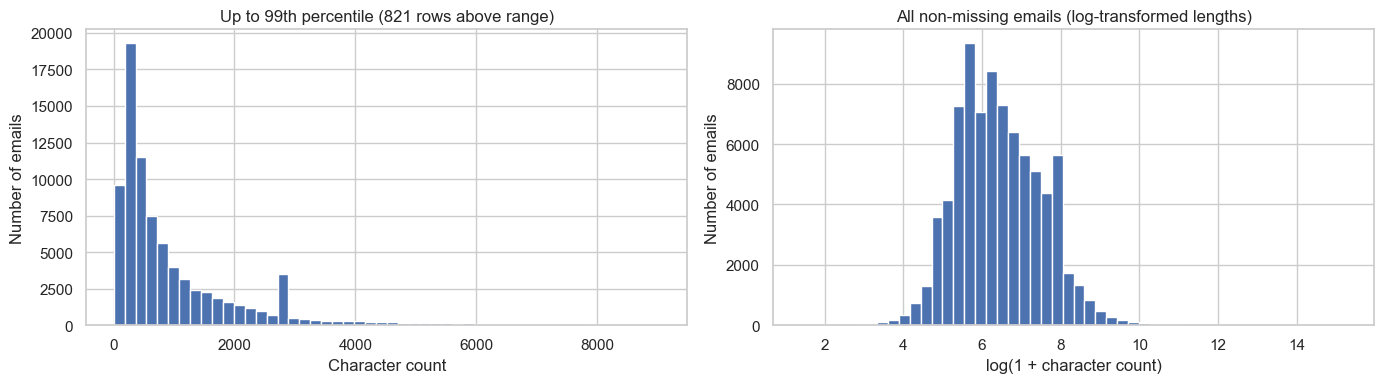

In [10]:
# Show lengths and the full distribution, including extreme values.
if not char_counts.empty:
    char_limit = char_counts.quantile(.99)
    above_limit = char_counts.gt(char_limit).sum()
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(char_counts[char_counts <= char_limit], bins=50, edgecolor='white')
    axes[0].set(
        title=f'Up to 99th percentile ({above_limit:,} rows above range)',
        xlabel='Character count', ylabel='Number of emails',
    )
    axes[1].hist(np.log1p(char_counts), bins=50, edgecolor='white')
    axes[1].set(
        title='All non-missing emails (log-transformed lengths)',
        xlabel='log(1 + character count)', ylabel='Number of emails',
    )
    plt.tight_layout()
    plt.show()


### Scatter plot and candidate cutoff


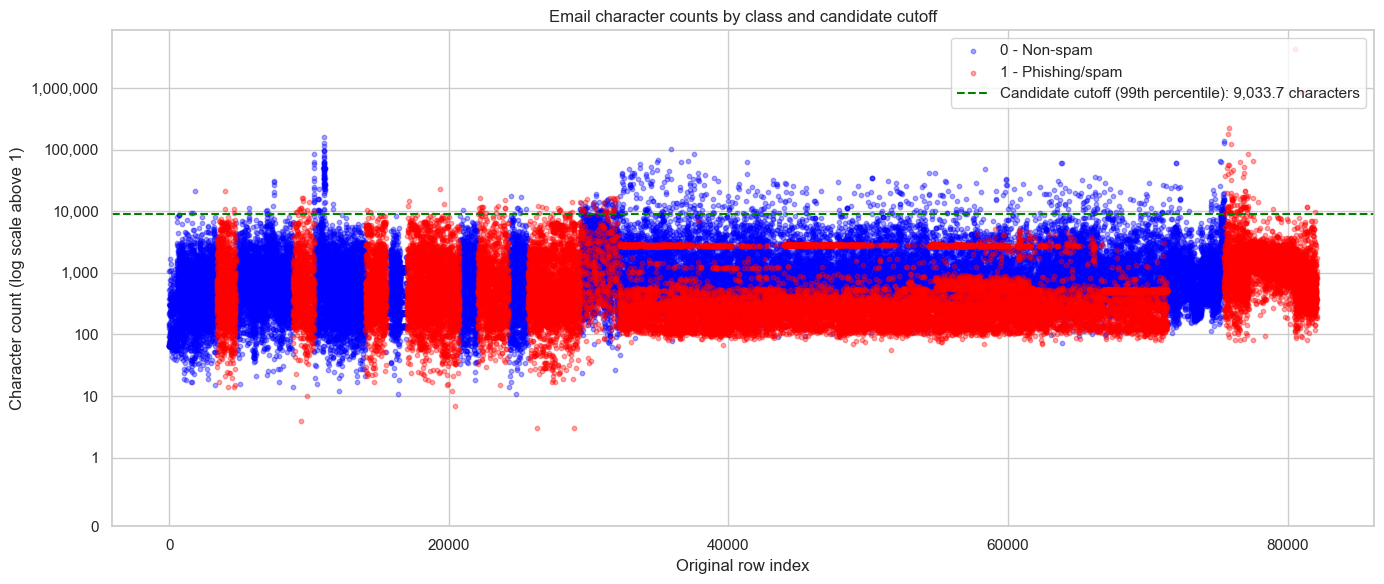

Emails above cutoff: 821


In [11]:
# Use the 99th percentile of character counts as the candidate cutoff.
char_review_threshold = char_counts.quantile(.99)

fig, ax = plt.subplots(figsize=(14, 6))
email_labels = df_phishing_email.loc[char_counts.index, 'label']
for value, color, name in [(0, 'blue', '0 - Non-spam'), (1, 'red', '1 - Phishing/spam')]:
    class_counts = char_counts[email_labels.eq(value)]
    ax.scatter(class_counts.index, class_counts, color=color, label=name, s=10, alpha=.35, rasterized=True)

ax.axhline(
    char_review_threshold, color='green', linestyle='--',
    label=f'Candidate cutoff (99th percentile): {char_review_threshold:,.1f} characters',
)
ax.set_yscale('symlog', linthresh=1)
ax.set_ylim(0, max(char_counts.max(), 1) * 2)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set(
    title='Email character counts by class and candidate cutoff',
    xlabel='Original row index', ylabel='Character count (log scale above 1)',
)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

print(f'Emails above cutoff: {char_counts.gt(char_review_threshold).sum():,}')


#### Observation: the length cutoff

The raw-text 99th percentile above is a inital estimate of cutoff. Section 3 calculates
a separate cap after cleaning and deduplication, using Dataset 3's own lengths.
Truncation retains each message's beginning and can remove useful later content;
it does not by itself establish improved classification performance.


In [12]:
df_combined = df_phishing_email.copy()
print(f'Week 2 initial preparation supplied {len(df_combined):,} rows from {DATA_PATH}')
display(df_combined['label'].value_counts(dropna=False).rename('prepared_rows').to_frame())

Week 2 initial preparation supplied 82,077 rows from /Users/debasishhalder/.cache/kagglehub/datasets/naserabdullahalam/phishing-email-dataset/versions/1/phishing_email.csv


,prepared_rows
label,
1,42844
0,39233


## 3. Data preprocessing methods

I cleaned and capped `word_text` and `text_combined`, while preserving original `text`.
The shared extractor produced six counts; I dropped the constant HTTP, HTTPS, and
sentence counts for Dataset 3. `MODEL_COUNT_COLUMNS` kept the six remaining features
aligned across the grouped split, full-corpus EDA, augmented matrices, and SVM pipelines.


### Preprocessing logic - flow

Week 2 combined CSV → remove blank text/duplicate text-label pairs → `df_combined` → clean/deduplicate/group → cap cleaned text → extract counts → drop three constant counts → `corpus` → grouped split → model inputs

1. **Validate:** Copy the source, require text and numeric 0/1 labels, and exclude missing labels.
2. **Clean:** Preserve original `text`; create `word_text` without markup, script/style contents, URLs, email addresses, numbers, or non-word punctuation.
3. **Deduplicate:** Remove unusable rows, exclude identical text with conflicting labels, and retain one row per whitespace-normalized exact duplicate.
4. **Group:** Hash normalized word sequences before truncation; use the full sequence when fewer than eight non-stopwords remain.
5. **Truncate:** Calculate the 99th-percentile cleaned length across the deduplicated corpus, round up to a whole character, cap `word_text`, copy it to `text_combined`, and drop `char_count`.
6. **Count:** Derive word and keyword counts from capped `word_text`; derive URL and sentence counts from original `text`. Protect feature words and negations when removing NLTK stopwords.
7. **Assemble:** Join six integer counts and filtered `clean_text`, then drop constant HTTP, HTTPS, and sentence counts; `MODEL_COUNT_COLUMNS` selects the remaining six.
8. **Split:** Create approximately 80/20 training/holdout partitions and three grouped CV folds within training data; report actual row counts below.
9. **Build inputs:** Section 4 fits TF-IDF on training text; Section 7 appends raw counts for inspection. SVM pipelines separately fit TF-IDF and count scaling within each CV training fold.

The cleaned-length cap was calculated before the split; it was not refitted inside CV.
The retained features are total word count and the urgency, account, threat, financial, and official term counts.
Labels and group IDs were excluded from predictors.


In [13]:
def truncate_email_text(frame, text_column="text_combined", percentile=.99):
    """Cap text using char_count's percentile and return a copy without char_count."""
    if not 0 < percentile <= 1:
        raise ValueError("percentile must be greater than 0 and at most 1.")

    cutoff = frame["char_count"].quantile(percentile)
    if pd.isna(cutoff):
        raise ValueError("char_count must contain non-missing lengths.")

    truncated = frame.copy()
    above_cutoff = truncated["char_count"].gt(cutoff).fillna(False)
    truncated.loc[above_cutoff, text_column] = (
        truncated.loc[above_cutoff, text_column]
        .astype("string")
        .str.slice(stop=int(np.ceil(cutoff)))
    )
    return truncated.drop(columns="char_count")


In [14]:
"""Shared text cleaning and count extraction for the phishing email dataset.

We are using a numeric label 0=legitimate, 1=phishing.  

"""

# Keep alphabetic words and internal apostrophes; digits and underscores are excluded.
TOKEN_PATTERN = r"(?u)\b[^\W\d_]+(?:'[^\W\d_]+)*\b"

WORD_RE = re.compile(TOKEN_PATTERN)

URL_RE = re.compile(r"\b(?:https?://|www\.)[^\s<>\"']+", re.I)

EMAIL_RE = re.compile(r"\b[^\s<>@]+@[^\s<>@]+\.[^\s<>@]+\b")

# Five fixed keyword categories complement the four structural/length features.
# Terms may overlap: a longer phrase and its component term can both contribute counts.
TERM_CATEGORIES = {
    "urgency": {
        "urgent", "immediate", "immediately", "action required", "attention required", "respond now",
        "expires", "expiring", "deadline", "limited time", "act now", "urgent action", "click",
        "here", "now", "free", "offer", "buy", "purchase", "donate", "subscribe", "register",
        "sign up", "get started", "learn more",
    },
    "account": {
        "verify", "verification", "authenticate", "confirm", "validate", "reactivate",
        "suspended", "blocked", "restricted", "limited", "unlock", "secure", "security",
        "access", "password", "login", "account", "username", "credential",
    },
    "threat": {
        "terminate", "deactivate", "delete", "removal", "suspend", "restriction",
        "warning", "risk", "compromised", "suspicious", "unauthorized", "disabled",
        "cancelled", "violation", "breach", "illegal",
    },
    "financial": {
        "claim", "prize", "winner", "won", "reward", "bonus", "payment", "refund",
        "deposit", "transfer", "transaction", "million", "inheritance", "lottery",
        "cash", "credit", "bank", "money", "fund", "balance",
    },
    "official": {
        "official", "authorized", "authentication", "notification", "notice", "alert",
        "department", "administration", "support", "service", "helpdesk",
    },
}

# HTMLParser calls the handlers below when feed() reads the HTML.


class VisibleText(HTMLParser):
    """Collect text outside script/style elements using HTMLParser callbacks.

    Attributes
    ----------
    parts : list[str]
        Accepted text fragments in encounter order; joined by visible_email_text.
    suppressed : int
        Number of currently open script/style elements used to suppress their data.

    Notes
    -----
    This is a text extractor, not a browser renderer: it does not interpret CSS,
    recover MIME attachments, or read text from images.
    """
    def __init__(self):
        """Initialize text fragments and the script/style suppression counter."""
        super().__init__(convert_charrefs=True)
        self.parts = []
        self.suppressed = 0

    def handle_starttag(self, tag, attrs):
        """Start suppressing text when a script or style element opens."""
        if tag in {"script", "style"}:
            self.suppressed += 1

    def handle_endtag(self, tag):
        """End suppression when a script or style element closes."""
        if tag in {"script", "style"} and self.suppressed:
            self.suppressed -= 1

    def handle_data(self, data):
        """Collect text only when the suppression counter is zero."""
        if not self.suppressed:
            self.parts.append(data)


def visible_email_text(value):
    """Extract visible text while preserving case and sentence punctuation.

    Parameters
    ----------
    value : scalar object
        Raw email value, usually str; a missing scalar returns an empty string.

    Returns
    -------
    str
        Text without parsed HTML tags or script/style contents, with entities decoded
        and curly apostrophes normalized. Case and punctuation are otherwise retained.
    """
    if pd.isna(value):
        return ""
    text = str(value)
    if re.search(r"</?[A-Za-z][^>]*>", text):
        parser = VisibleText()
        parser.feed(text)
        text = " ".join(parser.parts)
    return html.unescape(text).replace("\u2019", "'")


def clean_email_text(value):
    """Basic word-only view; keep the original text separately for URL features.

    Does not decode MIME/base64/quoted-printable or recover previously removed URLs.
    Preserves apostrophes/negation and word order; removes tags, URLs and addresses.

    Parameters
    ----------
    value : scalar object
        Raw email text or a missing scalar, passed through visible_email_text first.

    Returns
    -------
    str
        Case-folded, space-separated alphabetic/apostrophe tokens in original order.
        Stopwords are still present: the caller applies the shared stopword policy.
    """
    text = visible_email_text(value).casefold()
    text = URL_RE.sub(" ", text)
    text = EMAIL_RE.sub(" ", text)
    return " ".join(WORD_RE.findall(text))


def get_protected_feature_words():
    """Collect every token from the five keyword categories among the six features.

    Phrase components are protected , such as 'up' in 'sign up'. URL and
    sentence counts are extracted from original text, before stopword removal.

    Parameters
    ----------
    None
        Reads the shared TERM_CATEGORIES dictionary and text-normalization rules.

    Returns
    -------
    set[str]
        Unique normalized tokens from every category term, including phrase components.
        This is a set of words to retain, not an additional stopword source.
    """
    return {
        word
        for category in TERM_CATEGORIES.values()
        for term in category
        for word in clean_email_text(term).split()
    }


def get_effective_nltk_stopwords(stop_words=None):
    """Return NLTK English stopwords minus feature words and protected negations.

    Only NLTK stopwords or a subset are accepted; extra words are rejected, and negations are preserved.

    Parameters
    ----------
    stop_words : iterable[str] | None, default None
        None uses the full NLTK English list before applying feature-word and negation exclusions.

    Returns
    -------
    set[str]
        NLTK stopwords excluding protected feature words and negations.

    Raises
    ------
    ValueError
        If a supplied word is not in the NLTK English stopword set.
    LookupError or  the NLTK stopwords corpus has not been installed.
    """
    nltk_words = set(stopwords.words('english'))
    if stop_words is None:
        candidate_words = nltk_words
    else:
        candidate_words = {word.casefold() for word in stop_words}
        unsupported = candidate_words - nltk_words
        if unsupported:
            raise ValueError(f'Only NLTK English stopwords are allowed: {sorted(unsupported)}')

    # Preserve category words, including every component of a phrase.
    protected = get_protected_feature_words()
    # Protect common negation words so key sentiment signals are preserved.
    protected.update({'no', 'not', 'nor', 'never', 'cannot', "don't", "doesn't", "isn't", "won't"})
    protected.update(word for word in nltk_words if word.endswith("n't"))
    return candidate_words - protected

# One shared, corpus-supplied list; no custom email/header/HTML stopwords.
NLTK_STOP_WORDS = set(stopwords.words('english'))
PROTECTED_FEATURE_WORDS = get_protected_feature_words()
EFFECTIVE_STOP_WORDS = get_effective_nltk_stopwords()

assert EFFECTIVE_STOP_WORDS <= NLTK_STOP_WORDS
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)


In [15]:
COUNT_FEATURE_COLUMNS = [
    "http_url_count", "https_url_count", "sentence_count", "total_word_count",
    "urgency_terms_count", "account_terms_count", "threat_terms_count",
    "financial_terms_count", "official_terms_count",
]

# Matching hashes identify equal normalized text, not arbitrary near-duplicates.


def _hash(value):
    """Create a deterministic identifier for a supplied text representation.

    Parameters
    ----------
    value : str
        Text already normalized by the caller; encoded as UTF-8 before hashing.

    Returns
    -------
    str
        64-character SHA-256 hexadecimal digest. Equal input strings have equal hashes;
        hashing itself does not perform fuzzy matching or measure semantic similarity.
    """
    return hashlib.sha256(value.encode("utf-8")).hexdigest()

def prepare_email_corpus(frame, text_column="text_combined", label_column="label"):
    """Return cleaned, 99th-percentile-capped text without char_count or changes to the input.

    Deduplication: Remove exact duplicates, ignoring whitespace differences.
    Conflicts: Exclude identical text with conflicting labels.
    Grouping: Group normalized matches for splitting without deleting or relabeling them.

    Args:
        frame (pandas.DataFrame): Source emails and binary labels.
        text_column (str, default="text_combined"): Original email text column.
        label_column (str, default="label"): Numeric 0/1 label column; exclude missing labels.

    Returns:
        pandas.DataFrame: Unique emails with capped text_column and word_text, original text in text, int64 labels, content_hash, group_id, and a reset index.

    Raises:
        ValueError: Missing columns, invalid labels, or fewer than two classes after cleaning.
    """

    if not {text_column, label_column}.issubset(frame.columns):
        raise ValueError(f"Expected columns {text_column!r} and {label_column!r}.")

    data = frame.copy().reset_index(drop=True)

    data["text"] = data[text_column].fillna("").astype(str)

    target = pd.to_numeric(data[label_column], errors="raise")

    if not target.dropna().isin([0, 1]).all():
        raise ValueError("Labels must be 0 or 1; missing labels will be excluded.")

    data["label"] = target.astype("Int64")

    data = data[data["label"].notna()].copy()

    exact = data["text"].str.replace(r"\s+", " ", regex=True).str.strip()

    # Clean each email once; feature extraction reuses word_text.
    # Keep stopwords here to preserve positions for phrase matching.
    data["word_text"] = data["text"].map(clean_email_text)

    empty_mask = exact.str.casefold().isin(["", "empty"]) | data["word_text"].eq("")
    data = data[~empty_mask].copy()

    data["content_hash"] = exact.loc[data.index].map(_hash)

    counts = data.groupby("content_hash")["label"].nunique()
    consistent = data[~data["content_hash"].isin(counts.index[counts > 1])].copy()

    corpus = consistent.drop_duplicates("content_hash", keep="first").copy()

    grouping_stop_words = get_effective_nltk_stopwords()

    # The normalization creates grouping keys, not learned predictors or relabeled targets.
    def split_key(text):
        """Inner function split text, remove stopwords and then generate hash
        Parameters
        ----------
        text : str
            Normalized word_text; grouping_stop_words is inherited from the enclosing call.

        Returns
        -------
        str
            SHA-256 hash of the stopword-filtered sequence when at least eight tokens
            remain; otherwise hashes the full word sequence to keep short texts specific.
            Only identical resulting sequences are grouped; paraphrases may remain separate.
        """
        words = text.split()
        reduced = [w for w in words if w not in grouping_stop_words]
        # Keep short texts specific rather than group all generic short messages.
        return _hash(" ".join(reduced if len(reduced) >= 8 else words))

    # Keep identical normalized group keys in the same split.
    corpus["group_id"] = corpus["word_text"].map(split_key)

    corpus["label"] = corpus["label"].astype("int64")
    corpus = corpus.reset_index(drop=True)

    if corpus["label"].nunique() != 2:
        raise ValueError("Both classes are required after cleaning.")

    # Count cleaned characters for truncation; the helper drops char_count afterward.
    corpus["char_count"] = corpus["word_text"].str.len()
    corpus = truncate_email_text(corpus, text_column="word_text")
    corpus[text_column] = corpus["word_text"]
    return corpus


In [16]:
# Split original prepared rows before learning any vocabulary, IDF, or scaler.


def split_email_corpus(corpus, holdout_folds=5, cv_folds=3, random_state=42):
    """Approx. 1/holdout_folds held out; groups cannot cross holdout/CV splits.

    Parameters
    ----------
    corpus : pandas.DataFrame
        Prepared rows containing text, label in {0, 1}, and group_id.
    holdout_folds : int, default 5
        Number of grouped folds for the outer split; the first fold becomes holdout.
        Group sizes make the resulting fraction approximate rather than exactly 20%.
    cv_folds : int, default 3
        Number of stratified grouped folds constructed only within training rows.
    random_state : int, default 42
        Seed for reproducible shuffled splits.

    Returns
    -------
    train : pandas.DataFrame
        Training data with its row index reset.
    test : pandas.DataFrame
        Test data with its row index reset.
    splits : list of tuples
        Each tuple contains (fit_positions, validation_positions) for one
        cross-validation split. Both are integer arrays of row positions
        in train, accessed using train.iloc.

    Raises
    ------
    ValueError
        If too few groups exist per class or a resulting partition lacks a class.
    """

    if corpus.groupby("label")["group_id"].nunique().min() < holdout_folds:
        raise ValueError("Too few distinct groups per class for the requested holdout split.")

    splitter = StratifiedGroupKFold(
        n_splits=holdout_folds, shuffle=True, random_state=random_state
    )

    train_idx, test_idx = next(splitter.split(corpus["text"], corpus["label"], corpus["group_id"]))

    train = corpus.iloc[train_idx].reset_index(drop=True)
    test = corpus.iloc[test_idx].reset_index(drop=True)

    if train["label"].nunique() != 2 or test["label"].nunique() != 2:
        raise ValueError("This grouped holdout lacks a class; reconsider the split configuration.")

    if train.groupby("label")["group_id"].nunique().min() < cv_folds:
        raise ValueError("Too few training groups per class for CV.")

    cv = StratifiedGroupKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    splits = list(cv.split(train["text"], train["label"], train["group_id"]))

    for fit_idx, valid_idx in splits:
        if any(train.iloc[idx]["label"].nunique() != 2 for idx in (fit_idx, valid_idx)):
            raise ValueError("A grouped CV fold lacks a class; reconsider the split configuration.")

    return train, test, splits


In [17]:
def extract_count_features(corpus, stop_words=None, sentence_tokenizer=None):
    """Return (features, cleaned), preserving corpus.index and excluding labels.

    Args:
        corpus (pd.DataFrame): Original text and precleaned word_text
        stop_words (iterable[str] | None): NLTK English subset or full list if None; protect category words, phrase components, and negations.
        sentence_tokenizer (callable | None): Maps text to a sequence of sentences; defaults to nltk.sent_tokenize.

    Counting rules:
        Words: Count retained alphabetic/apostrophe tokens, excluding URLs, addresses, numbers, and punctuation.
        Terms: Count repeated and overlapping matches; phrases require original word adjacency.
        URLs: Count every raw HTTP/HTTPS occurrence, including those in HTML attributes.
        Sentences: Use visible text without URLs/addresses, before stopword filtering.

    Returns:
        features (pd.DataFrame): Shape (n_emails, 9), with int64 counts in COUNT_FEATURE_COLUMNS order.
        cleaned (pd.Series): Stopword-filtered strings named clean_text.
    """

    if stop_words is None:
        from nltk.corpus import stopwords
        stop_words = set(stopwords.words("english"))

    if sentence_tokenizer is None:
        from nltk.tokenize import sent_tokenize
        sentence_tokenizer = sent_tokenize

    # Check tokenizer availability once.
    sentence_tokenizer("Tokenizer check.")

    # Normalize terms like the stored email words.
    terms = {name: [tuple(clean_email_text(t).split()) for t in sorted(values)]
             for name, values in TERM_CATEGORIES.items()}

    # Protect all phrase components.
    protected = {w for category in terms.values() for term in category for w in term}

    # Preserve category words and negations.
    effective_stop_words = get_effective_nltk_stopwords(stop_words)
    assert effective_stop_words.isdisjoint(protected)

    max_n = max(len(term) for category in terms.values() for term in category)

    raw = corpus["text"]
    records, cleaned = [], []

    for text, word_text in zip(raw, corpus["word_text"]):
        # Keep positions before stopword removal.
        words = word_text.split()
        kept = [(i, w) for i, w in enumerate(words) if w not in effective_stop_words]
        filtered = [w for _, w in kept]
        cleaned.append(" ".join(filtered))

        occurrences = Counter((w,) for w in filtered)

        # Require original adjacency for phrase matches.
        for n in range(2, max_n + 1):
            for i in range(len(kept) - n + 1):
                window = kept[i:i+n]
                if window[-1][0] - window[0][0] == n - 1:
                    occurrences[tuple(w for _, w in window)] += 1

        # Keep punctuation for sentence boundaries.
        visible = EMAIL_RE.sub(" ", URL_RE.sub(" ", visible_email_text(text))).strip()

        record = {
            "http_url_count": len(re.findall(r"\bhttp://[^\s<>\"']+", text, re.I)),
            "https_url_count": len(re.findall(r"\bhttps://[^\s<>\"']+", text, re.I)),
            "sentence_count": len(sentence_tokenizer(visible)) if visible else 0,
            "total_word_count": len(filtered),
        }

        record.update({f"{name}_terms_count": sum(occurrences[t] for t in category)
                       for name, category in terms.items()})
        records.append(record)

    features = pd.DataFrame(records, columns=COUNT_FEATURE_COLUMNS, index=raw.index).astype("int64")

    return features, pd.Series(cleaned, index=raw.index, name="clean_text")


def prepare_count_dataset(frame, stop_words=None, sentence_tokenizer=None):
    """Return the prepared corpus with raw text, six features, and cleaned text.

    Input columns: text_combined and label. Uses no learned word vocabulary or
    label-based feature selection

    Parameters
    ----------
    frame : pandas.DataFrame
        Original email data with text_combined and numeric label columns.
    stop_words : iterable[str] | None, default None
        Optional NLTK subset passed to extract_count_features.
    sentence_tokenizer : callable(str) -> sequence[str] | None, default None
        Optional sentence tokenizer passed to extract_count_features.

    Returns
    -------
    pandas.DataFrame
        Prepared corpus containing retained text/metadata, int64 label, all six
        int64 count columns, and clean_text. Original text and word_text remain
        available for the classifier.
    """
    corpus = prepare_email_corpus(frame)
    features, cleaned = extract_count_features(corpus, stop_words, sentence_tokenizer)
    # Re-running on a frame containing feature columns replaces them, not duplicates.
    corpus = corpus.drop(columns=COUNT_FEATURE_COLUMNS + ["clean_text"], errors="ignore")
    return pd.concat([corpus, features, cleaned], axis=1)


In [18]:
# Build the corpus once, then create independent training/holdout partitions.
# Targets and group identifiers are kept alongside the rows but excluded from predictors.

corpus = prepare_count_dataset(df_combined)

In [19]:
print(corpus.info())
print(corpus.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82076 entries, 0 to 82075
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   text_combined          82076 non-null  object
 1   label                  82076 non-null  int64 
 2   text                   82076 non-null  object
 3   word_text              82076 non-null  object
 4   content_hash           82076 non-null  object
 5   group_id               82076 non-null  object
 6   http_url_count         82076 non-null  int64 
 7   https_url_count        82076 non-null  int64 
 8   sentence_count         82076 non-null  int64 
 9   total_word_count       82076 non-null  int64 
 10  urgency_terms_count    82076 non-null  int64 
 11  account_terms_count    82076 non-null  int64 
 12  threat_terms_count     82076 non-null  int64 
 13  financial_terms_count  82076 non-null  int64 
 14  official_terms_count   82076 non-null  int64 
 15  clean_text         

In [20]:
display(corpus.describe())

# Summarize cleaned, truncated email lengths, including spaces; preserve missing text.
corpus_char_counts = corpus['word_text'].astype('string').str.len()
print(f"Missing text: {corpus_char_counts.isna().sum():,} rows")
print(f"Empty text: {corpus_char_counts.eq(0).sum():,} rows")
display(corpus_char_counts.dropna().astype('int64').describe(percentiles=[.25, .5, .75, .9, .95, .99, .999]).to_frame('char_count'))


,label,http_url_count,https_url_count,sentence_count,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
count,82076.000000,82076.0,82076.0,82076.0,82076.000000,82076.000000,82076.000000,82076.000000,82076.000000,82076.000000
mean,0.521992,0.0,0.0,1.0,126.334422,0.726851,0.607181,0.168295,1.022430,0.488669
std,0.499519,0.0,0.0,0.0,164.415671,1.812991,2.053302,0.890333,3.687292,1.294956
min,0.000000,0.0,0.0,1.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.0,0.0,1.0,33.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.0,0.0,1.0,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.0,0.0,1.0,162.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,0.0,0.0,1.0,1707.000000,66.000000,54.000000,38.000000,108.000000,38.000000


Missing text: 0 rows
Empty text: 0 rows


,char_count
count,82076.000000
mean,931.571166
std,1245.992822
min,2.000000
25%,239.000000
50%,483.000000
75%,1182.000000
90%,2089.000000
95%,3225.250000
99%,7846.250000


In [21]:
# Drop Dataset 3's constant URL and sentence counts before splitting or analysis.
corpus = corpus.drop(columns=['http_url_count', 'https_url_count', 'sentence_count'], errors='ignore')
MODEL_COUNT_COLUMNS = [name for name in COUNT_FEATURE_COLUMNS if name in corpus.columns]


In [22]:
print(corpus.columns)

Index(['text_combined', 'label', 'text', 'word_text', 'content_hash',
       'group_id', 'total_word_count', 'urgency_terms_count',
       'account_terms_count', 'threat_terms_count', 'financial_terms_count',
       'official_terms_count', 'clean_text'],
      dtype='object')


**Grouped split:** `split_email_corpus()` created approximately 80/20 training/holdout
partitions and three CV folds within training data. Section 4 then fitted TF-IDF on
training text, and Section 7 appended the six counts. SVM tuning fitted its own
TF-IDF and count scaling separately within each CV training fold.


In [23]:
train_df, holdout_df, cv_splits = split_email_corpus(
    corpus,
    holdout_folds=5,  # Approximately 80% training and 20% holdout.
    cv_folds=3,
    random_state=RANDOM_STATE,
)
test_df = holdout_df  # Both names refer to the same held-out partition.

# Metadata and targets stay outside the feature matrices.
y_train = train_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_test = test_df[TARGET_COLUMN].to_numpy(dtype=np.int64)
y_holdout = y_test
groups_train = train_df['group_id'].to_numpy()
groups_test = test_df['group_id'].to_numpy()
X_train_text = train_df[TEXT_COLUMN].copy()
X_holdout_text = test_df[TEXT_COLUMN].copy()

assert set(groups_train).isdisjoint(groups_test)
assert set(train_df['content_hash']).isdisjoint(test_df['content_hash'])
for fit_idx, valid_idx in cv_splits:
    assert set(groups_train[fit_idx]).isdisjoint(groups_train[valid_idx])

split_summary = pd.DataFrame({
    'rows': [len(train_df), len(test_df)],
    'share_of_clean_corpus': [len(train_df) / len(corpus), len(test_df) / len(corpus)],
    'safe': [(y_train == 0).sum(), (y_test == 0).sum()],
    'phishing': [(y_train == 1).sum(), (y_test == 1).sum()],
}, index=['Training', 'Holdout / test'])
display(split_summary)


,rows,share_of_clean_corpus,safe,phishing
Training,65635,0.799686,30957,34678
Holdout / test,16441,0.200314,8276,8165


## 4. Create the TF-IDF data

Use the training and holdout rows created by the grouped split in Section 3.

- **Input:** Read the prepared `word_text` column; email cleaning is already complete.
- **Stopwords:** Apply `EFFECTIVE_STOP_WORDS`, the NLTK English list with category words, phrase components, and negations protected.
- **Training:** Use `fit_transform()` to learn the vocabulary and IDF weights from training emails and create `X_train_tfidf`.
- **Holdout:** Use the same fitted vectorizer's `transform()` to create `X_test_tfidf`, preserving the training vocabulary and IDF weights.
- **Output:** Store sparse `float32` matrices with identical feature columns and rows aligned with `y_train` and `y_test`; `MAX_FEATURES_TFIDF` sets the vocabulary cap.

Sections 5–6 analyze a full copy of `corpus` with the six count features transformed by `log1p`. Section 7 appends those raw counts to the TF-IDF matrices to create `X_train_augmented` and `X_test_augmented`; Section 8 checks their shapes, feature order, and label alignment.

For SVM tuning in Section 12, the shared preprocessing defined in Section 9 receives the prepared DataFrames and refits TF-IDF within each CV training fold. Validation and holdout rows use the corresponding fitted transformation; the matrices created here are kept in memory for inspection or direct training with the fixed holdout.

Reference: [scikit-learn TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).


In [24]:
# Learn the in-memory TF-IDF vocabulary and IDF only from training emails.
# The classification CV pipeline will independently refit this preprocessing within each fold.

tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    token_pattern=TOKEN_PATTERN,
    stop_words=sorted(EFFECTIVE_STOP_WORDS),  # NLTK only, with feature words excluded.
    ngram_range=NGRAM_RANGE,
    max_features=MAX_FEATURES_TFIDF,
    min_df=MIN_DF,
    dtype=np.float32,
)

# Fit only on training text.
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train_text).tocsr()
# Transform holdout text using the training vocabulary.
X_test_tfidf = tfidf_vectorizer.transform(X_holdout_text).tocsr()
X_holdout_tfidf = X_test_tfidf
tfidf_terms = tfidf_vectorizer.get_feature_names_out()
tfidf_feature_names = np.array(['tfidf__' + term for term in tfidf_terms])

y_train_tfidf, y_holdout_tfidf = y_train, y_test  # Familiar Week 4 aliases.

# Sparse DataFrames provide named TF-IDF columns without densifying the data.
tfidf_train_df = pd.DataFrame.sparse.from_spmatrix(X_train_tfidf, columns=tfidf_terms)
tfidf_test_df = pd.DataFrame.sparse.from_spmatrix(X_test_tfidf, columns=tfidf_terms)

print(f'TF-IDF features after NLTK stopword filtering: {len(tfidf_terms):,}')
print(f'Training TF-IDF: {X_train_tfidf.shape}; holdout TF-IDF: {X_test_tfidf.shape}')

# Check every unigram and bigram component: no removable stopword may remain.
tfidf_vocabulary_words = {word for term in tfidf_terms for word in term.split()}
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
print('Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.')


TF-IDF features after NLTK stopword filtering: 5,000
Training TF-IDF: (65635, 5000); holdout TF-IDF: (16441, 5000)
Verified: TF-IDF contains no effective stopwords; protected feature words are not filtered.


## 5. Univariate and Bivariate analysis related methods

I copied `corpus` to `corpus_eda` and applied `np.log1p` once to the derived
`MODEL_COUNT_COLUMNS`. Text, labels, metadata, and the original counts stayed unchanged.

Sections 5–6 use all Dataset 3 corpus rows, including future holdout rows.
These are exploratory full-corpus summaries, not training-only analyses.


In [25]:
# Transform only the six count columns in a separate copy of the full corpus.
corpus_eda = corpus.copy()
corpus_eda[MODEL_COUNT_COLUMNS] = np.log1p(corpus_eda[MODEL_COUNT_COLUMNS])


### Analysis methods

I analyzed the six retained log1p counts by label using full-corpus histograms,
correlations, violin/box plots, and KDE. The pairplot used up to 1,000 class-balanced
rows with histogram diagonals. Constant features were excluded from correlations
and pairplots; constant class values used box plots and were skipped for KDE.
Histogram heights showed email counts; labels and metadata were excluded from predictor axes.


In [26]:
def perform_univariate_analysis(df, kde=True):
    """Plot retained log1p counts by label; use KDE only when each class varies."""
    features = [name for name in MODEL_COUNT_COLUMNS if name in df.columns]
    if not features:
        return
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Univariate Analysis: log1p Counts', fontsize=10, y=1.02)
    axes = axes.flatten()

    for ax, feature in zip(axes, features):
        # Constant class values cannot support a density estimate.
        use_kde = kde and df.groupby('label')[feature].nunique().gt(1).all()
        sns.histplot(data=df, x=feature, hue='label', multiple='stack',
                     bins=35, kde=use_kde, ax=ax)
        ax.set(title=f'Distribution of {feature}', xlabel=f'log1p({feature})', ylabel='Emails')

    for ax in axes[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [27]:
def perform_bivariate_analysis(df, include_pairplot=True, include_violin=True):
    """Plot retained count relationships and class distributions; skip constant densities."""
    features = [name for name in MODEL_COUNT_COLUMNS if name in df.columns]
    if not features:
        return
    varying_features = [name for name in features if df[name].nunique() > 1]
    plot_labels = {feature: f'log1p({feature})' for feature in features}

    # Constant features have undefined correlations and no useful pairwise variation.
    if varying_features:
        correlation_matrix = df[varying_features].corr().rename(index=plot_labels, columns=plot_labels)
        plt.figure(figsize=(12, 8))
        sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
                    fmt='.2f', square=True, vmin=-1, vmax=1)
        plt.title('Correlation Matrix of log1p Counts')
        plt.tight_layout()
        plt.show()

    if include_pairplot and len(varying_features) > 1:
        pairplot_df = create_balanced_sample(
            df[varying_features + ['label']], sample_size=1000, random_state=RANDOM_STATE,
        ).rename(columns=plot_labels)
        print(f'Pairplot sample: {len(pairplot_df):,} corpus rows, balanced by class.')
        pair_grid = sns.pairplot(
            pairplot_df, vars=[plot_labels[name] for name in varying_features],
            hue='label', diag_kind='hist', height=1.8,
            plot_kws={'alpha': 0.35, 's': 10},
        )
        for ax in pair_grid.axes.flat:
            ax.set_xlabel(ax.get_xlabel(), fontsize=8)
            ax.set_ylabel(ax.get_ylabel(), fontsize=8)
            ax.tick_params(labelsize=8)
        plt.show()

    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    if include_violin:
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
        fig.suptitle('Class Distributions: log1p Counts by Label', fontsize=10, y=1.02)
        for ax, feature in zip(axes.flat, features):
            if df.groupby('label')[feature].nunique().gt(1).all():
                sns.violinplot(data=df, x='label', y=feature, cut=0, ax=ax)
            else:
                sns.boxplot(data=df, x='label', y=feature, ax=ax)
            ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
                   title=f'{feature} by Label')
        for ax in axes.flat[len(features):]:
            fig.delaxes(ax)
        plt.tight_layout()
        plt.show()

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('Box Plots: log1p Counts by Label', fontsize=10, y=1.02)
    for ax, feature in zip(axes.flat, features):
        sns.boxplot(data=df, x='label', y=feature, ax=ax)
        ax.set(xlabel='Label (0 = Safe, 1 = Phishing)', ylabel=plot_labels[feature],
               title=f'{feature} by Label')
    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [28]:
def perform_kde_analysis(df):
    """Plot retained log1p count densities for classes with at least two distinct values."""
    features = [name for name in MODEL_COUNT_COLUMNS if name in df.columns]
    if not features:
        return
    n_cols = 3
    n_rows = (len(features) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows), squeeze=False)
    fig.suptitle('KDE Plots: log1p Counts by Label', fontsize=10, y=1.02)

    for ax, feature in zip(axes.flat, features):
        varying = df.groupby('label')[feature].nunique().gt(1)
        density_data = df[df['label'].isin(varying.index[varying])]
        if not density_data.empty:
            sns.kdeplot(data=density_data, x=feature, hue='label', hue_order=[0, 1],
                        cut=0, warn_singular=False, ax=ax)
        if not varying.all():
            ax.text(0.5, 0.95, 'Constant classes omitted', transform=ax.transAxes,
                    ha='center', va='top', fontsize=9)
        ax.set(title=f'KDE of {feature}', xlabel=f'log1p({feature})')

    for ax in axes.flat[len(features):]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()


In [29]:
def analyze_phishing_email_Univariate_data(df):
    """Display histograms and KDE for the corpus copy's six log1p counts by label."""
    print('Performing Univariate Analysis...')
    perform_univariate_analysis(df)


def analyze_phishing_email_Bivariate_data(df, include_kde=False):
    """Display count relationships and class comparisons, with optional separate KDE plots."""
    print('Performing Bivariate Analysis...')
    perform_bivariate_analysis(df)
    if include_kde:
        print('Performing KDE Analysis...')
        perform_kde_analysis(df)


In [30]:
def create_balanced_sample(df, sample_size=1000, random_state=42):
    """Sample equally by label without replacement, capped by the smaller class; shuffle rows."""
    safe = df[df['label'] == 0]
    phishing = df[df['label'] == 1]
    per_class = min(sample_size // 2, len(safe), len(phishing))
    sample = pd.concat([
        safe.sample(n=per_class, random_state=random_state),
        phishing.sample(n=per_class, random_state=random_state),
    ])
    return sample.sample(frac=1, random_state=random_state).reset_index(drop=True)


In [31]:
# Summarize log1p counts; zero_percent is the percentage of emails without each feature.
count_feature_summary = corpus_eda[MODEL_COUNT_COLUMNS].describe().T
count_feature_summary['zero_percent'] = corpus_eda[MODEL_COUNT_COLUMNS].eq(0).mean() * 100
print(f'log1p-count summary: {len(MODEL_COUNT_COLUMNS)} features, {len(corpus_eda):,} corpus emails.')
display(count_feature_summary.round(3))


log1p-count summary: 6 features, 82,076 corpus emails.


,count,mean,std,min,25%,50%,75%,max,zero_percent
total_word_count,82076.0,4.292,1.045,0.693,3.526,4.22,5.094,7.443,0.000
urgency_terms_count,82076.0,0.343,0.544,0.000,0.000,0.00,0.693,4.205,66.127
account_terms_count,82076.0,0.236,0.538,0.000,0.000,0.00,0.000,4.007,79.906
threat_terms_count,82076.0,0.085,0.292,0.000,0.000,0.00,0.000,3.664,90.689
financial_terms_count,82076.0,0.274,0.675,0.000,0.000,0.00,0.000,4.691,81.075
official_terms_count,82076.0,0.231,0.484,0.000,0.000,0.00,0.000,3.664,78.030


## 6. Univariate and Bivariate analysis using the six derived features

I passed `corpus_eda` directly to both analysis functions. Class summaries and
plots used all corpus rows, except the balanced 1,000-row pairplot.
Means and medians were in log1p units; correlations were between transformed
features. I did not apply a second log transform.


#### Observation : Univariate analysis

Use Dataset 3's displayed distributions and class summaries to compare the six
features. Values are in `log1p(count)` units; zeros remain zero and histogram heights
are email counts. Account for class sizes when comparing the colored segments.
Dataset 1's means and conclusions do not describe this run.

I dropped HTTP and HTTPS counts (all zero) and sentence count (always one) because they provided no variation.


#### Observation : Bivariate analysis

Use Dataset 3's heatmap and plots to assess length relationships, keyword co-occurrence,
and class overlap. Correlations are between log1p-transformed features, not with the label.
The balanced pairplot does not show actual class proportions; sparse-feature boxplot
outliers are not necessarily data errors. Record numerical findings after running this section.


In [32]:
# Compare the mean and median of log1p counts by label across the full corpus.
count_class_comparison = (
    corpus_eda.groupby('label')[MODEL_COUNT_COLUMNS]
    .agg(['mean', 'median']).T.rename(columns={0: 'Safe', 1: 'Phishing'})
)
print('log1p-count summaries by class (0 = Safe, 1 = Phishing):')
display(count_class_comparison.round(3))


log1p-count summaries by class (0 = Safe, 1 = Phishing):


label                          Safe  Phishing
total_word_count      mean    4.543     4.062
                      median  4.533     3.912
urgency_terms_count   mean    0.255     0.424
                      median  0.000     0.000
account_terms_count   mean    0.194     0.275
                      median  0.000     0.000
threat_terms_count    mean    0.104     0.067
                      median  0.000     0.000
financial_terms_count mean    0.143     0.395
                      median  0.000     0.000
official_terms_count  mean    0.227     0.235
                      median  0.000     0.000

In [33]:
corpus_eda.columns

Index(['text_combined', 'label', 'text', 'word_text', 'content_hash',
       'group_id', 'total_word_count', 'urgency_terms_count',
       'account_terms_count', 'threat_terms_count', 'financial_terms_count',
       'official_terms_count', 'clean_text'],
      dtype='object')

In [34]:
corpus_eda.describe() 

,label,total_word_count,urgency_terms_count,account_terms_count,threat_terms_count,financial_terms_count,official_terms_count
count,82076.000000,82076.000000,82076.000000,82076.000000,82076.000000,82076.000000,82076.000000
mean,0.521992,4.292193,0.343002,0.236065,0.084879,0.274432,0.230964
std,0.499519,1.044912,0.544374,0.538425,0.291658,0.674978,0.484128
min,0.000000,0.693147,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,3.526361,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,4.219508,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,5.093750,0.693147,0.000000,0.000000,0.000000,0.000000
max,1.000000,7.443078,4.204693,4.007333,3.663562,4.691348,3.663562


Performing Univariate Analysis...


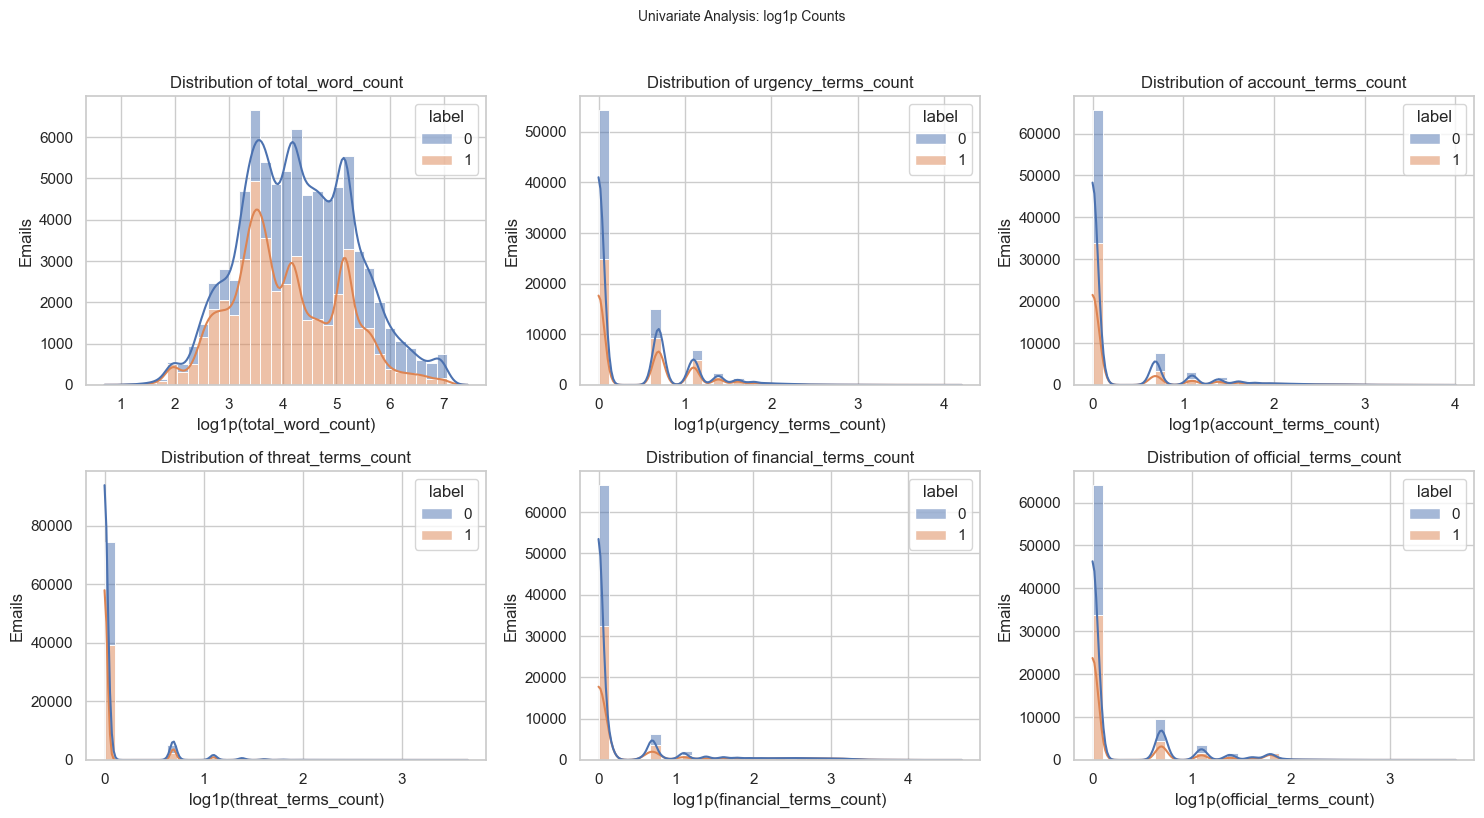

Performing Bivariate Analysis...


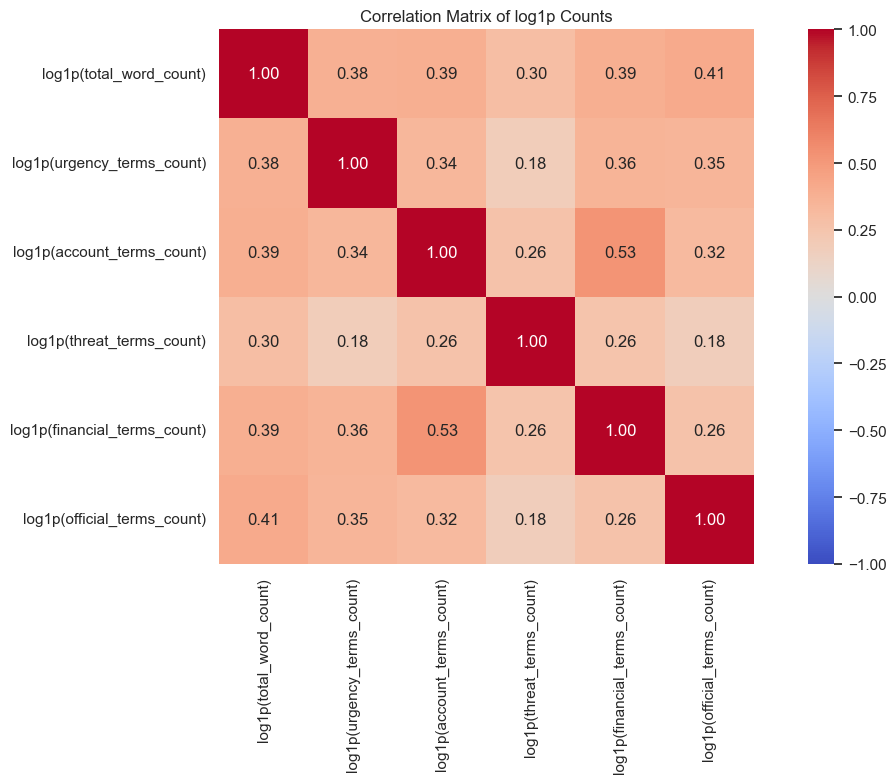

Pairplot sample: 1,000 corpus rows, balanced by class.


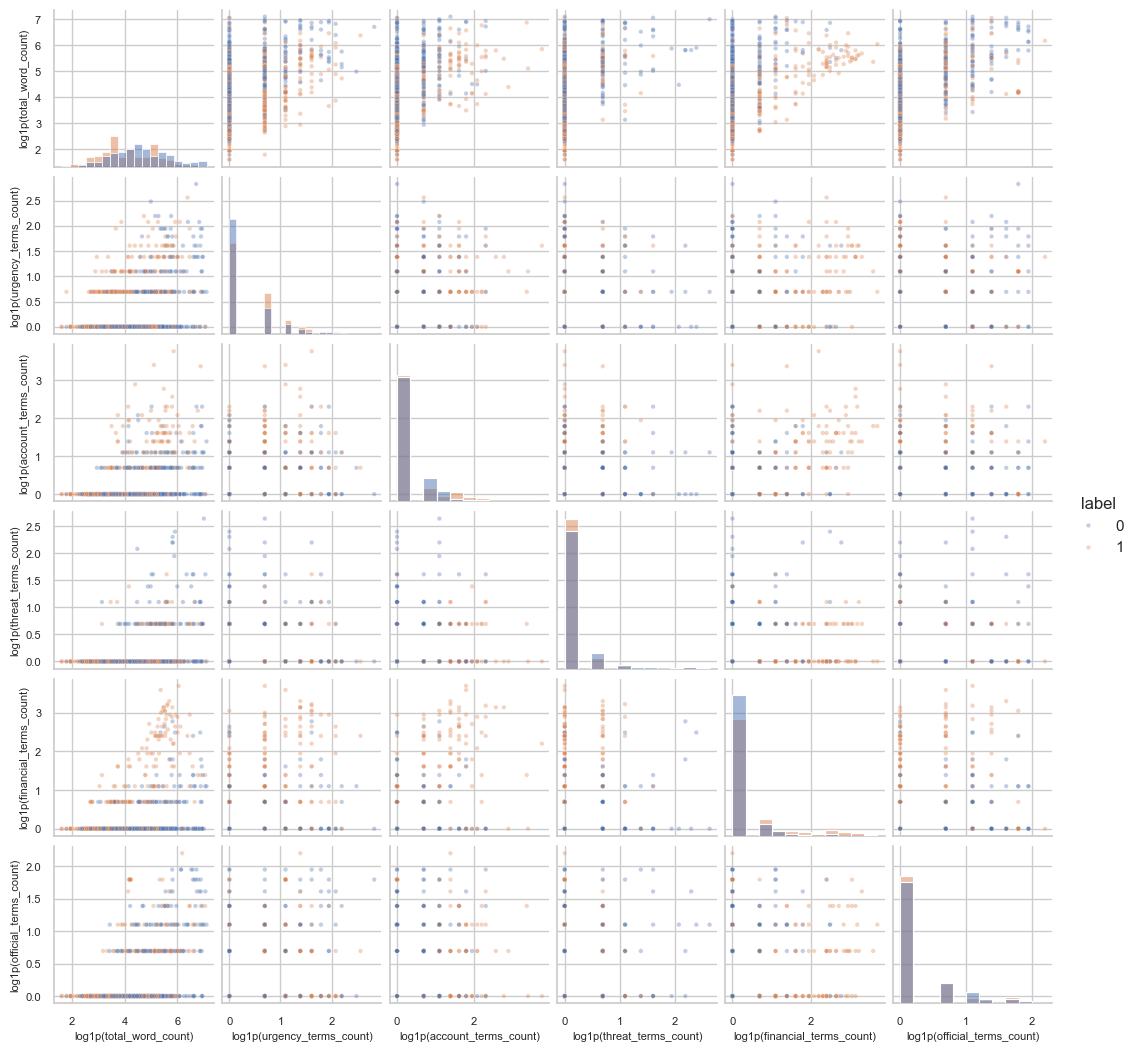

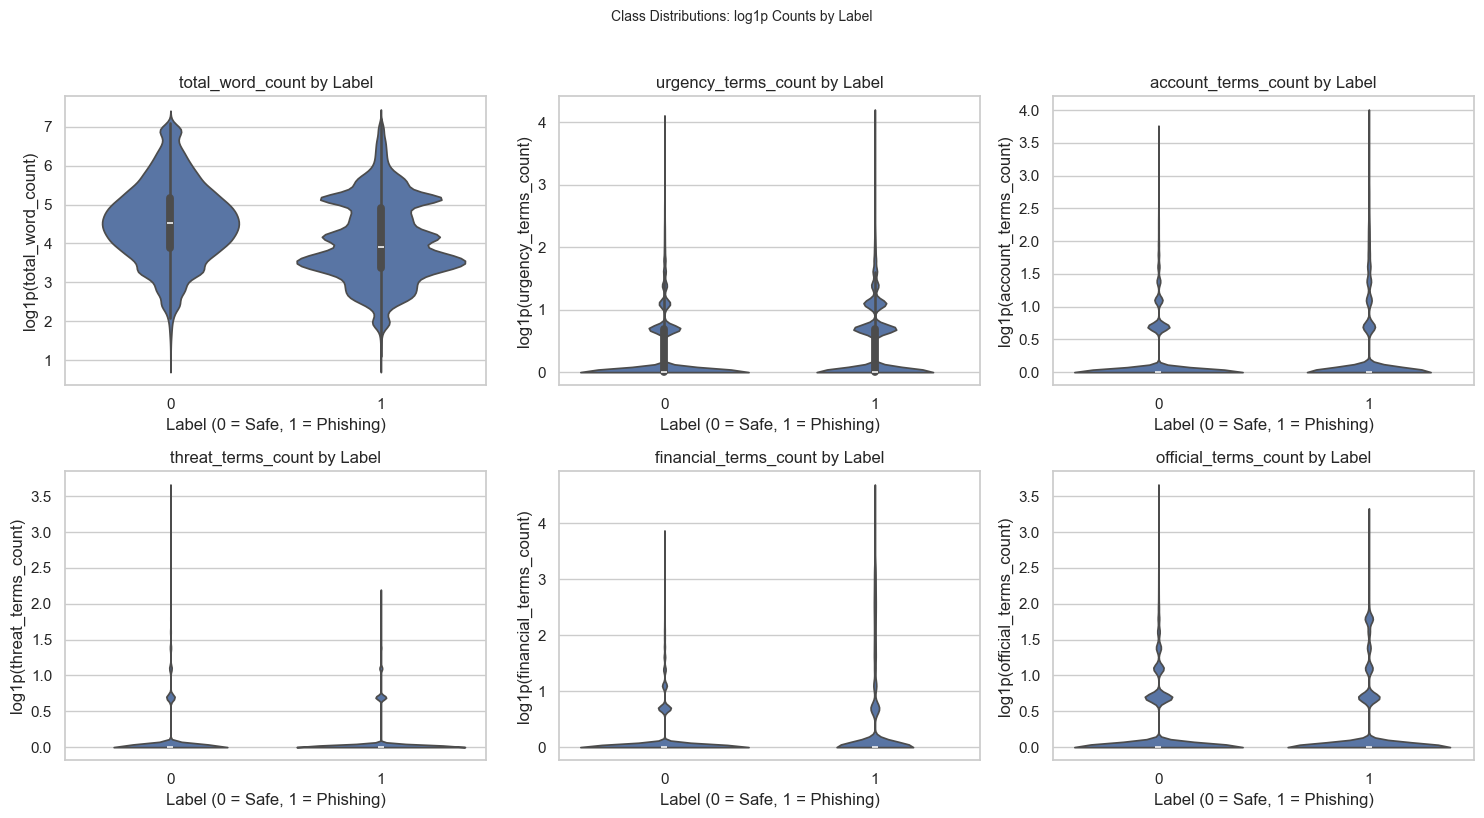

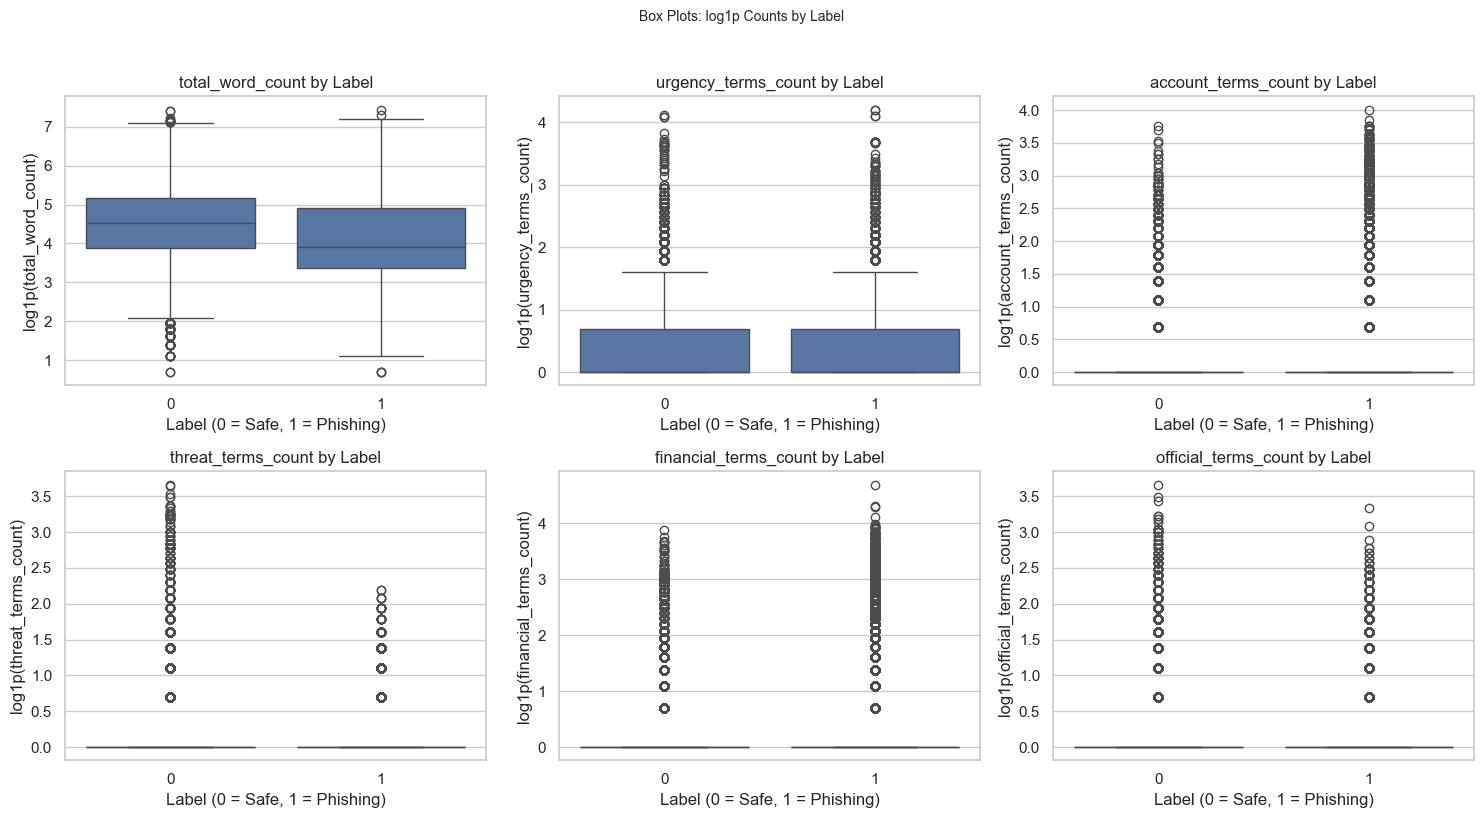

Performing KDE Analysis...


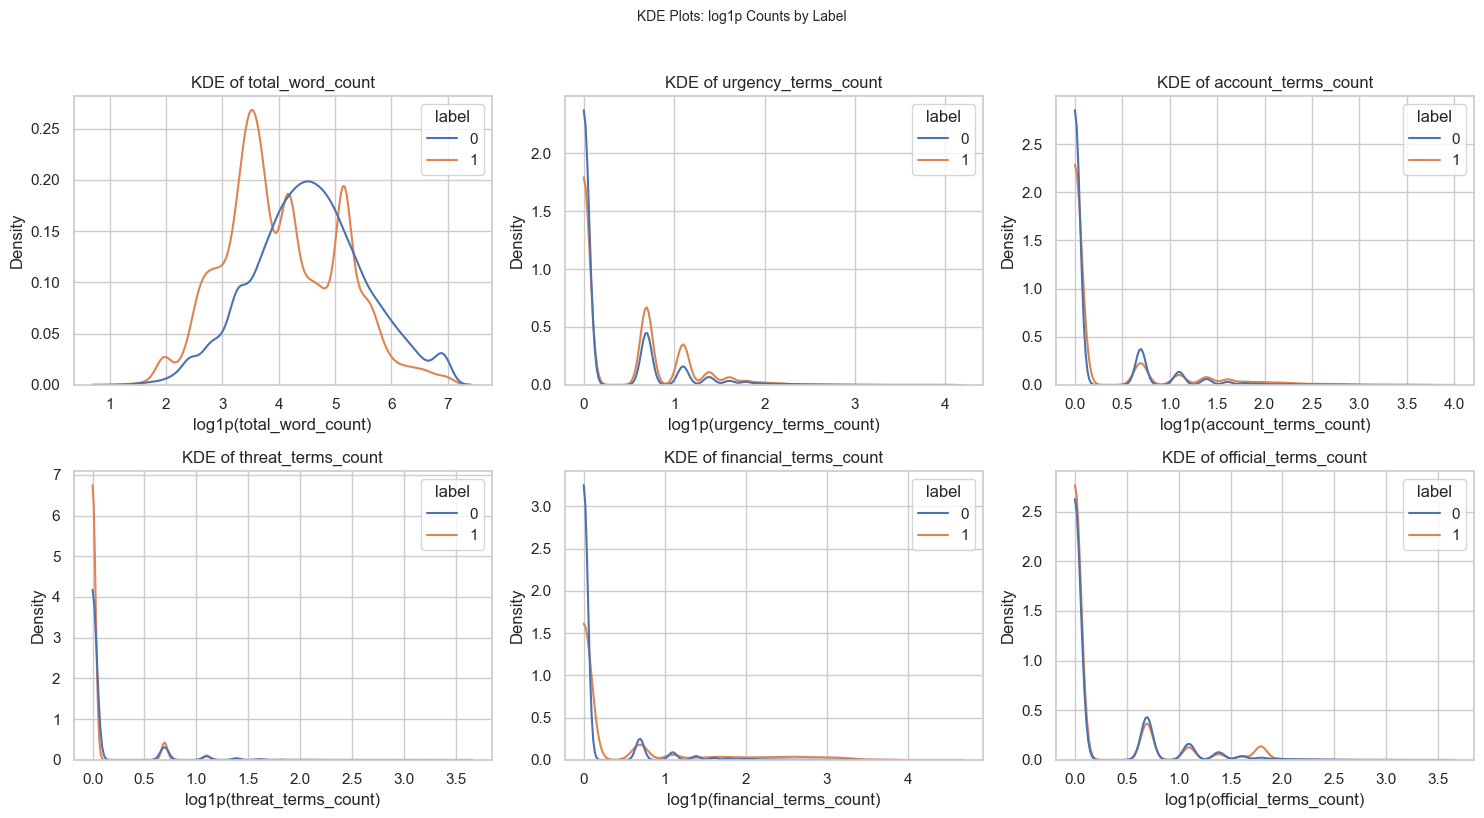

In [35]:
# Pass the full transformed corpus; each helper selects the six counts and label.
analyze_phishing_email_Univariate_data(corpus_eda)
analyze_phishing_email_Bivariate_data(corpus_eda, include_kde=True)


In [36]:
# Lets drop the corpus_eda datframe to save memory since we have already performed the analysis and have the results.

del corpus_eda

#### Why combine the six features with TF-IDF

The counts capture email length and keyword patterns; TF-IDF adds vocabulary
features learned from training emails. 
From the correlation matrix we see these is some information but the correlation is very poor. We look for correlation in features nearer to 0.7 or 0.8 but we see the coeficients only one of them is 0.53 and another one is 0.41. so we will not have good perfromance as there is lack of correlation between these manually derived features. 

So we will use TF-IDF and then add these features to it and perfrom our training and classification


## 7. Create the augmented feature vector: TF-IDF + six engineered features

In [37]:
# Create the reusable raw augmented vector and preserve a catalog of its column order.
# Sparse horizontal stacking keeps the 5,000 TF-IDF columns from becoming a dense matrix.

assert EFFECTIVE_STOP_WORDS <= set(stopwords.words('english'))
assert EFFECTIVE_STOP_WORDS.isdisjoint(PROTECTED_FEATURE_WORDS)
assert tfidf_vectorizer.get_params()['stop_words'] == sorted(EFFECTIVE_STOP_WORDS)
assert EFFECTIVE_STOP_WORDS.isdisjoint(tfidf_vocabulary_words)

# Append the six original count features in the declared order; keep everything sparse.
X_train_counts = sparse.csr_matrix(train_df[MODEL_COUNT_COLUMNS].to_numpy(dtype=np.float32))
X_test_counts = sparse.csr_matrix(test_df[MODEL_COUNT_COLUMNS].to_numpy(dtype=np.float32))
count_feature_names = np.array(['count__' + name for name in MODEL_COUNT_COLUMNS])

X_train_augmented = sparse.hstack([X_train_tfidf, X_train_counts], format='csr', dtype=np.float32)
X_test_augmented = sparse.hstack([X_test_tfidf, X_test_counts], format='csr', dtype=np.float32)
X_holdout_augmented = X_test_augmented
augmented_feature_names = np.concatenate([tfidf_feature_names, count_feature_names])
augmented_feature_catalog = pd.DataFrame({
    'column_index': np.arange(len(augmented_feature_names)),
    'feature_name': augmented_feature_names,
    'feature_type': ['TF-IDF'] * len(tfidf_terms) + ['Count'] * len(MODEL_COUNT_COLUMNS),
})
# Aliases used by modeling and reporting.
X_train, X_test = X_train_augmented, X_test_augmented
X_holdout = X_holdout_augmented
feature_names = augmented_feature_names
feature_catalog = augmented_feature_catalog

# Verify the vector size, feature order, and row alignment before modeling.
n_count_features = len(MODEL_COUNT_COLUMNS)
assert n_count_features > 0
assert X_train_augmented.shape == (len(y_train), len(augmented_feature_names))
assert X_test_augmented.shape == (len(y_test), len(augmented_feature_names))
assert len(augmented_feature_names) == X_train_tfidf.shape[1] + n_count_features
assert list(augmented_feature_names[-n_count_features:]) == list(count_feature_names)
assert len(set(augmented_feature_names)) == len(augmented_feature_names)
for matrix in (X_train_augmented, X_test_augmented):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()

augmentation_summary = pd.DataFrame({
    'rows': [X_train_augmented.shape[0], X_test_augmented.shape[0]],
    'TF-IDF features': [X_train_tfidf.shape[1], X_test_tfidf.shape[1]],
    'additional count features': [len(MODEL_COUNT_COLUMNS)] * 2,
    'augmented features': [X_train_augmented.shape[1], X_test_augmented.shape[1]],
}, index=['Training', 'Holdout / test'])
print(f'TF-IDF uses {len(EFFECTIVE_STOP_WORDS)} effective NLTK stopwords; feature-word overlap: 0.')
display(augmentation_summary)
print(f'The {n_count_features} appended features and their positions in the new vector:')
display(augmented_feature_catalog.tail(n_count_features))


TF-IDF uses 172 effective NLTK stopwords; feature-word overlap: 0.


,rows,TF-IDF features,additional count features,augmented features
Training,65635,5000,6,5006
Holdout / test,16441,5000,6,5006


The 6 appended features and their positions in the new vector:


,column_index,feature_name,feature_type
5000,5000,count__total_word_count,Count
5001,5001,count__urgency_terms_count,Count
5002,5002,count__account_terms_count,Count
5003,5003,count__threat_terms_count,Count
5004,5004,count__financial_terms_count,Count
5005,5005,count__official_terms_count,Count


## 8. Data ready for the next step

| Variable | Contents |
|---|---|
| `X_train_tfidf`, `X_test_tfidf` | Sparse TF-IDF features only |
| `X_train_counts`, `X_test_counts` | The original six numeric count features |
| `X_train_augmented`, `X_test_augmented` | New sparse vectors: TF-IDF followed by six raw count features |
| `X_train`, `X_test`, `X_holdout` | Compatible aliases for the augmented matrices |
| `augmented_feature_names`, `augmented_feature_catalog` | Ordered names and positions in the new vector |
| `y_train`, `y_test` | Aligned labels; Safe = 0, Phishing = 1 |
| `tfidf_terms`, `feature_names`, `feature_catalog` | Column names in matrix order |
| `tfidf_train_df`, `tfidf_test_df` | Named sparse TF-IDF DataFrames |
| `tfidf_vectorizer` | Fitted training vocabulary and IDF weights |
| `train_df`, `test_df` | Text, count features, labels, and source-row metadata |
| `groups_train`, `groups_test`, `cv_splits` | Group IDs and three training CV splits |
| `corpus_eda` | Temporary log1p corpus copy used in Sections 5–6 and deleted after analysis |
| `count_feature_summary`, `count_class_comparison` | Full-corpus summaries of the six log1p count features |

`X_holdout` and `y_holdout` are aliases for the test partition. Row position `i`
in each matrix matches position `i` in its labels and source DataFrame.

The prepared matrices can be used for training and final holdout evaluation.
For cross-validation or tuning, use `cv_splits` with a pipeline that fits
a new TF-IDF vectorizer inside each fold using `train_df[TEXT_COLUMN]`. Using the
already fitted TF-IDF matrix for CV would expose validation-fold vocabulary and
IDF statistics. In this notebook, EDA and the length-cap calculation used the
full corpus, so the holdout comparison remained exploratory.
Reference: [scikit-learn guidance on preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

The SVM methods in Section 9 receive `train_df` and combine TF-IDF with the six
count features. Inside each training fold, the pipeline refits TF-IDF and applies
`log1p` followed by `StandardScaler(with_mean=False)` to the counts.
The prepared matrices and original count columns stay unchanged.


In [38]:
# Final shape, alignment, and numeric checks. No classifier is trained here.
assert X_train.shape == (len(y_train), len(feature_names))
assert X_test.shape == (len(y_test), len(feature_names))
assert len(tfidf_terms) == X_train_tfidf.shape[1] == X_test_tfidf.shape[1]
assert len(np.unique(feature_names)) == len(feature_names)
assert X_train.shape[1] == X_train_tfidf.shape[1] + len(MODEL_COUNT_COLUMNS)
for matrix in (X_train_tfidf, X_test_tfidf, X_train_counts, X_test_counts, X_train, X_test):
    assert sparse.isspmatrix_csr(matrix)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all()
    assert (matrix.data >= 0).all()
assert np.array_equal(y_train, train_df[TARGET_COLUMN].to_numpy())
assert np.array_equal(y_test, test_df[TARGET_COLUMN].to_numpy())

ready_summary = pd.DataFrame([
    {'feature_set': 'TF-IDF only', 'training_rows': X_train_tfidf.shape[0],
     'holdout_rows': X_test_tfidf.shape[0], 'features': X_train_tfidf.shape[1]},
    {'feature_set': 'Six count features', 'training_rows': X_train_counts.shape[0],
     'holdout_rows': X_test_counts.shape[0], 'features': X_train_counts.shape[1]},
    {'feature_set': 'TF-IDF + counts (X_train / X_test)', 'training_rows': X_train.shape[0],
     'holdout_rows': X_test.shape[0], 'features': X_train.shape[1]},
])
display(ready_summary)
print('Data preparation and analysis complete. The matrices and labels are ready.')


,feature_set,training_rows,holdout_rows,features
0,TF-IDF only,65635,16441,5000
1,Six count features,65635,16441,6
2,TF-IDF + counts (X_train / X_test),65635,16441,5006


Data preparation and analysis complete. The matrices and labels are ready.


## 9. Using SVM methods to do classification

Classify Dataset 3 emails as Safe (0) or Phishing (1) using sparse TF-IDF plus six counts.
Each method returns an unfitted pipeline for prepared DataFrames.

| Method | Model | Main settings |
|---|---|---|
| `create_linear_svm(...)` | LinearSVC | `C`, `class_weight` |
| `create_kernel_svm(..., kernel="rbf")` | RBF SVC | `C`, `gamma` |
| `create_kernel_svm(..., kernel="poly")` | Polynomial SVC | `C`, `gamma`, `degree`, `coef0` |

Pipelines clone `tfidf_vectorizer` settings and fit vocabulary, IDF, and count scaling
on training rows. Counts use `log1p` and `StandardScaler(with_mean=False)`; TF-IDF
keeps L2 normalization. Use `train_df` for fitting/CV and `test_df` for evaluation.
`count_columns=None` uses TF-IDF alone; the existing `X_train`/`X_test` retain raw counts.

**Kernel trick:** SVC computes similarities in an implicit feature space without manually expanding features.

- RBF: $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$; larger `gamma` makes similarity more local.
- Polynomial: $K(x,z)=(\gamma x^Tz+\mathrm{coef0})^{\mathrm{degree}}$.
- Larger `C` penalizes margin violations more; smaller `C` gives stronger regularization.

References: [SVM guide](https://scikit-learn.org/stable/modules/svm.html),
[LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html),
[SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).


In [39]:
# SVM dependencies; Memory caches preprocessing and parallel_config controls workers.
import time
from tempfile import TemporaryDirectory

from joblib import Memory, cpu_count, parallel_config

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    root_mean_squared_error,
    f1_score, roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, make_scorer, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay,
)


In [40]:
def make_svm_features(vectorizer, *, text_column="word_text", count_columns=None):
    """Build unfitted TF-IDF preprocessing with optional log1p-scaled counts.

    Args:
        vectorizer (TfidfVectorizer): Settings template; fitted vocabulary/IDF is discarded.
        text_column (str): Prepared text column in the input DataFrame.
        count_columns (sequence[str] | None): Unique count predictors; None uses TF-IDF only.

    Returns:
        ColumnTransformer: TF-IDF followed by counts; drops unselected columns.

    Output shape is (n_rows, vocabulary_size + n_counts), sparse for this dataset.
    Counts use log1p and StandardScaler(with_mean=False), fitted on training rows.

    Raises:
        TypeError: count_columns is a string.
        ValueError: Count columns repeat or include text_column.
    """
    if isinstance(count_columns, str):
        raise TypeError("count_columns must be a list of column names, not a string.")
    count_columns = list(count_columns) if count_columns is not None else []
    if text_column in count_columns or len(set(count_columns)) != len(count_columns):
        raise ValueError("Count columns must be unique and exclude the text column.")

    # Pass text as a one-dimensional Series.
    transformers = [("tfidf", clone(vectorizer), text_column)]
    if count_columns:
        # Fit count scaling within each training fold.
        count_preparation = Pipeline([
            ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler(with_mean=False)),
        ])
        transformers.append(("counts", count_preparation, count_columns))

    # Keep TF-IDF before counts and drop unselected columns.
    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",  # Drop labels, raw text copies, hashes, and row IDs.
        sparse_threshold=1.0,
    )


In [41]:
def create_linear_svm(
    vectorizer, *, text_column="word_text", count_columns=None,
    C=1.0, class_weight=None, max_iter=10_000, random_state=42,
):
    """Create an unfitted TF-IDF/counts -> LinearSVC pipeline.

    Args:
        vectorizer (TfidfVectorizer): Settings template cloned by make_svm_features.
        text_column (str): Prepared text column.
        count_columns (sequence[str] | None): Optional counts, transformed with log1p and scaling.
        C (float): Positive inverse regularization strength; larger C penalizes margin violations more.
        class_weight (dict | str | None): Class penalties; 'balanced' uses inverse class frequencies.
        max_iter (int): Solver iteration limit.
        random_state (int): Seed for randomized solver operations.

    Returns:
        Pipeline: Unfitted features -> svm steps; LinearSVC uses squared-hinge loss.

    Fit/predict on prepared DataFrames; fitted labels and margins have shape (n_rows,).
    Positive margins favor Phishing=1; scores are not probabilities.
    """
    return Pipeline([
        ("features", make_svm_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("svm", LinearSVC(
            C=C, class_weight=class_weight, dual="auto",
            max_iter=max_iter, random_state=random_state,
        )),
    ])


In [42]:
def create_kernel_svm(
    vectorizer, *, kernel="rbf", text_column="word_text", count_columns=None,
    C=1.0, gamma="scale", degree=2, coef0=1.0, class_weight=None,
    cache_size=256, random_state=42,
):
    """Create an unfitted TF-IDF/counts -> RBF or polynomial SVC pipeline.

    Args:
        vectorizer (TfidfVectorizer): Settings template cloned by make_svm_features.
        kernel (str): 'rbf' or 'poly'.
        text_column (str): Prepared text column.
        count_columns (sequence[str] | None): Optional counts, transformed with log1p and scaling.
        C (float): Positive inverse regularization strength.
        gamma (str | float): Kernel coefficient; 'scale' derives it from transformed training data.
        degree (int): Polynomial exponent; ignored for RBF.
        coef0 (float): Polynomial offset; ignored for RBF.
        class_weight (dict | str | None): Class penalties; 'balanced' uses inverse class frequencies.
        cache_size (float): Kernel-cache limit in MB, separate from preprocessing caches.
        random_state (int): Passed to SVC; inactive with probability=False.

    Returns:
        Pipeline: Unfitted features -> svm steps, accepting prepared DataFrames.

    Fitted labels and margins have shape (n_rows,); probability estimation is disabled.

    Raises:
        ValueError: kernel is neither 'rbf' nor 'poly'.
    """
    if kernel not in {"rbf", "poly"}:
        raise ValueError("Use kernel='rbf' or 'poly'; use create_linear_svm for a linear SVM.")
    return Pipeline([
        ("features", make_svm_features(
            vectorizer, text_column=text_column, count_columns=count_columns,
        )),
        ("svm", SVC(
            kernel=kernel, C=C, gamma=gamma, degree=degree, coef0=coef0,
            class_weight=class_weight, probability=False, cache_size=cache_size,
            random_state=random_state,
        )),
    ])


## 10. Reusable tuning and evaluation methods

1. `tune_svm_model`: validate grouped folds, test `svm__` settings, and refit the best mean phishing-F1 candidate.
2. `summarize_svm_searches`: compare each family's CV winner and fit times.
3. `evaluate_svm_model`: return metrics, reports, predictions, and decision scores; optionally plot confusion, ROC, and precision-recall charts.

Shared settings support Section 11 baselines and Section 12 tuning. ROC-AUC and
average precision (AP) use decision margins; RMSE uses predicted labels.
The default margin boundary is zero. Holdout results do not select settings or thresholds.


In [43]:
def tune_svm_model(
    pipeline, training_frame, cv_splits, param_grid, *,
    target_column="label", group_column="group_id", n_jobs=1, verbose=0,
    return_train_score=False,
):
    """Run grouped training CV and refit the highest mean phishing-F1 candidate.

    Args:
        pipeline (Pipeline): Unfitted features -> svm template; cloned before fitting.
        training_frame (pd.DataFrame): Prepared predictors, binary labels, and group IDs.
        cv_splits (iterable[tuple]): Fit/validation positional indices into training_frame.
        param_grid (dict | list[dict]): Candidate settings with svm__ prefixes.
        target_column (str): Label column; Safe=0 and Phishing=1.
        group_column (str): Non-missing IDs that must not overlap within a fold.
        n_jobs (int): Parallel search workers.
        verbose (int): Search progress level.
        return_train_score (bool): Also score each candidate on its fold's training rows.

    Returns:
        GridSearchCV: Best refitted pipeline/settings, fold metrics, refit_time_, and elapsed_seconds_.

    TF-IDF and scaling fit within each fold; holdout data is excluded.
    cv_results_ stores RMSE as negative scores; all timings use seconds.

    Raises:
        ValueError: Invalid labels/groups, metadata predictors, or invalid/overlapping folds.
    """
    labels = training_frame[target_column].to_numpy()
    groups = training_frame[group_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Training labels must contain both Safe=0 and Phishing=1.")
    if pd.isna(groups).any():
        raise ValueError("Training group IDs cannot be missing.")

    # Exclude labels and metadata from predictors.
    feature_transformer = pipeline.named_steps["features"]
    forbidden_columns = {target_column, group_column, "input_row", "content_hash", "copies"}
    for _, _, columns in feature_transformer.transformers:
        selected = [columns] if isinstance(columns, str) else list(columns)
        if forbidden_columns.intersection(selected):
            raise ValueError("The feature pipeline includes a label or metadata column.")

    splits = list(cv_splits)
    if len(splits) < 2:
        raise ValueError("Provide at least two grouped cross-validation splits.")
    # Validate positions, both classes, and row/group separation.
    for fold, (fit_idx, valid_idx) in enumerate(splits, start=1):
        fit_idx, valid_idx = np.asarray(fit_idx), np.asarray(valid_idx)
        for indices in (fit_idx, valid_idx):
            if (indices.ndim != 1 or indices.dtype.kind not in "iu" or len(indices) == 0
                    or np.any(indices < 0) or np.any(indices >= len(training_frame))
                    or len(np.unique(indices)) != len(indices)):
                raise ValueError(f"Fold {fold} has invalid row indices for training_frame.")
            if set(labels[indices]) != {0, 1}:
                raise ValueError(f"Fold {fold} needs both classes in fit and validation rows.")
        if set(fit_idx).intersection(valid_idx):
            raise ValueError(f"Fold {fold} shares rows between fit and validation.")
        if set(groups[fit_idx]).intersection(groups[valid_idx]):
            raise ValueError(f"Fold {fold} shares email groups between fit and validation.")

    # Record all metrics; select by mean validation F1.
    scoring = {
        "accuracy": "accuracy",
        "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
        "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
        "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
        "roc_auc": "roc_auc",  # Uses decision_function, not predicted class labels.
        "average_precision": "average_precision",
        "balanced_accuracy": "balanced_accuracy",
        "rmse": "neg_root_mean_squared_error",  # RMSE of predicted 0/1 labels.

    }
    search = GridSearchCV(
        estimator=clone(pipeline), param_grid=param_grid, scoring=scoring,
        refit="f1", cv=splits, n_jobs=n_jobs, return_train_score=return_train_score,
        error_score="raise", verbose=verbose,
    )
    start = time.perf_counter()
    search.fit(training_frame, labels)
    search.elapsed_seconds_ = time.perf_counter() - start
    return search


In [44]:
def summarize_svm_searches(searches):
    """Summarize each family's CV winner, sorted by descending validation F1.

    Args:
        searches (dict[str, GridSearchCV]): Completed searches from tune_svm_model.

    Returns:
        pd.DataFrame: One row per family with parameters, CV metrics, training F1, and timings.

    Missing training F1 is NaN; timings use seconds and holdout scores are excluded.

    Raises:
        ValueError: searches is empty.
    """
    rows = []
    for name, search in searches.items():
        # Read all metrics from the selected candidate.
        best = search.best_index_
        scores = search.cv_results_
        rows.append({
            "model": name,
            "training_f1": scores.get("mean_train_f1", np.full(len(scores["params"]), np.nan))[best],
            "cv_f1": scores["mean_test_f1"][best],
            "cv_f1_std": scores["std_test_f1"][best],
            "CV_RMSE": -scores["mean_test_rmse"][best],
            "CV_Mean_Fit_Time_Seconds": scores["mean_fit_time"][best],
            "CV_Std_Fit_Time_Seconds": scores["std_fit_time"][best],
            "CV_Refit_Time_Seconds": search.refit_time_,
            "cv_precision": scores["mean_test_precision"][best],
            "cv_recall": scores["mean_test_recall"][best],
            "cv_roc_auc": scores["mean_test_roc_auc"][best],
            "cv_average_precision": scores["mean_test_average_precision"][best],
            "search_seconds": search.elapsed_seconds_,
            "best_parameters": search.best_params_,
        })
    if not rows:
        raise ValueError("Pass at least one fitted SVM search.")
    return pd.DataFrame(rows).sort_values("cv_f1", ascending=False).reset_index(drop=True)


In [45]:
def evaluate_svm_model(
    fitted_model, evaluation_frame, *, target_column="label", name="SVM", plot=True,
):
    """Score a fitted binary SVM using its default predictions, without refitting.

    Args:
        fitted_model (Pipeline | GridSearchCV): Fitted model with classes_=[0, 1] and decision_function.
        evaluation_frame (pd.DataFrame): Prepared predictors and labels containing both classes.
        target_column (str): Observed label column; Safe=0 and Phishing=1.
        name (str): Model label for metrics and plots.
        plot (bool): Show confusion-matrix, ROC, and precision-recall charts.

    Returns:
        dict: metrics, classification_report, confusion_matrix, predictions, and decision_scores.

    Metrics include accuracy, error rate, balanced accuracy, precision, recall, F1, RMSE, ROC-AUC, and AP.
    The report is a DataFrame; the (2, 2) confusion matrix is [[TN, FP], [FN, TP]].
    Labels and margins have shape (n_rows,); positive margins favor Phishing=1.
    RMSE uses labels; ROC-AUC and average_precision (AP) use margins, not probabilities.

    Raises:
        ValueError: Evaluation labels or model classes are not exactly {0, 1}.
    """
    labels = evaluation_frame[target_column].to_numpy()
    if pd.isna(labels).any() or set(labels) != {0, 1}:
        raise ValueError("Evaluation requires both Safe=0 and Phishing=1 for ROC-AUC.")
    if not np.array_equal(fitted_model.classes_, np.array([0, 1])):
        raise ValueError("The fitted model must use Safe=0 and Phishing=1.")

    predictions = fitted_model.predict(evaluation_frame)
    scores = fitted_model.decision_function(evaluation_frame)
    metrics = {
        "model": name, "rows": len(labels),
        "accuracy": accuracy_score(labels, predictions),
        "rmse": root_mean_squared_error(labels, predictions),
        "error_rate": np.mean(labels != predictions),
        "balanced_accuracy": balanced_accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
        "roc_auc": roc_auc_score(labels, scores),
        "average_precision": average_precision_score(labels, scores),
    }
    report = pd.DataFrame(classification_report(
        labels, predictions, labels=[0, 1], target_names=["Safe", "Phishing"],
        output_dict=True, zero_division=0,
    )).T
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(17, 4))
        ConfusionMatrixDisplay(matrix, display_labels=["Safe", "Phishing"]).plot(
            ax=axes[0], cmap="Blues", colorbar=False,
        )
        RocCurveDisplay.from_predictions(labels, scores, name=name, ax=axes[1])
        PrecisionRecallDisplay.from_predictions(labels, scores, name=name, ax=axes[2])
        axes[0].set_title(f"{name}: confusion matrix")
        axes[1].set_title("ROC using SVM decision scores")
        axes[2].set_title("Precision-recall using SVM decision scores")
        plt.tight_layout()
        plt.show()
    return {
        "metrics": metrics, "classification_report": report,
        "confusion_matrix": matrix, "predictions": predictions, "decision_scores": scores,
    }


In [46]:
# Optional helpers; the current quick search already records RMSE and refits its winners.

def add_cv_rmse_scores(cv_results, training_labels, cv_splits):
    """Return a copy with recovered or verified per-fold classification RMSE.

    Args:
        cv_results (dict | pd.DataFrame): Full-precision fold recall, balanced accuracy, precision, and F1.
        training_labels (array-like): Binary labels in the original training-row order.
        cv_splits (sequence[tuple]): Original fit/validation positional indices.

    Returns:
        pd.DataFrame: Split/mean/std RMSE and rank_test_rmse; training RMSE requires training scores.

    Recover error counts from recall/class balance and cross-check precision/F1.
    RMSE scores remain negative; standard deviations remain nonnegative.

    Raises:
        ValueError or AssertionError: Missing fold classes or inconsistent scores/counts.
    """
    results = pd.DataFrame(cv_results).copy()
    labels = np.asarray(training_labels)
    for partition, index_position in [('test', 1), ('train', 0)]:
        if f'split0_{partition}_recall' not in results:
            continue  # Skip partitions whose scores were not collected.
        fold_rmse = []
        for fold, split in enumerate(cv_splits):
            fold_labels = labels[np.asarray(split[index_position])]
            n_safe = int(np.sum(fold_labels == 0))
            n_phishing = int(np.sum(fold_labels == 1))
            if not n_safe or not n_phishing:
                raise ValueError('Both labels are required in every training/validation fold.')
            recall = results[f'split{fold}_{partition}_recall'].to_numpy(dtype=float)
            balanced_accuracy = results[f'split{fold}_{partition}_balanced_accuracy'].to_numpy(dtype=float)
            tp = np.rint(recall * n_phishing).astype(int)
            # Recover TN from balanced_accuracy = (recall + TNR) / 2.
            tn = np.rint((2 * balanced_accuracy - recall) * n_safe).astype(int)
            assert ((0 <= tp) & (tp <= n_phishing)).all()
            assert ((0 <= tn) & (tn <= n_safe)).all()
            fn, fp = n_phishing - tp, n_safe - tn
            precision = np.divide(tp, tp + fp, out=np.zeros(len(results)), where=(tp + fp) != 0)
            f1 = 2 * tp / (2 * tp + fp + fn)
            np.testing.assert_allclose(recall, tp / n_phishing, atol=1e-12)
            np.testing.assert_allclose(balanced_accuracy, (tp / n_phishing + tn / n_safe) / 2, atol=1e-12)
            np.testing.assert_allclose(results[f'split{fold}_{partition}_precision'], precision, atol=1e-12)
            np.testing.assert_allclose(results[f'split{fold}_{partition}_f1'], f1, atol=1e-12)
            rmse = np.sqrt((fp + fn) / len(fold_labels))
            key = f'split{fold}_{partition}_rmse'
            if key in results:
                np.testing.assert_allclose(-results[key], rmse, atol=1e-12)
            results[key] = -rmse  # GridSearchCV uses negative loss scores.
            fold_rmse.append(rmse)
        fold_rmse = np.asarray(fold_rmse)
        results[f'mean_{partition}_rmse'] = -fold_rmse.mean(axis=0)
        results[f'std_{partition}_rmse'] = fold_rmse.std(axis=0)
    # Rank less-negative RMSE higher; ties share the best rank.
    results['rank_test_rmse'] = results['mean_test_rmse'].rank(ascending=False, method='min').astype(int)
    return results


def fit_and_evaluate_svm_candidate(model_name, candidate_id, pipeline, parameters,
                                   training_frame, evaluation_frame, *, target_column='label'):
    """Fit one fixed configuration without caching, then evaluate it; unused by quick mode.

    Args:
        model_name (str): Model-family label.
        candidate_id (int): Candidate's CV row identifier.
        pipeline (Pipeline): Template cloned before fitting, with preprocessing caching disabled.
        parameters (dict): Settings chosen using training CV, with pipeline prefixes.
        training_frame (pd.DataFrame): Prepared training predictors and binary labels.
        evaluation_frame (pd.DataFrame): Separate evaluation rows with the same schema.
        target_column (str): Binary label column in both frames.

    Returns:
        dict: Model/candidate IDs, parameters, fitted estimator, evaluation, and fit/evaluation seconds.

    Fit timing includes preprocessing and training; evaluation uses evaluate_svm_model.
    """
    model = clone(pipeline).set_params(memory=None, **parameters)
    start = time.perf_counter()
    model.fit(training_frame, training_frame[target_column].to_numpy())
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    result = evaluate_svm_model(model, evaluation_frame, target_column=target_column,
                                name=model_name, plot=False)
    evaluation_seconds = time.perf_counter() - start
    return {
        'model': model_name, 'candidate_id': candidate_id, 'parameters': parameters,
        'estimator': model, 'evaluation': result,
        'fit_seconds': fit_seconds, 'evaluation_seconds': evaluation_seconds,
    }


### Shared experiment settings

Both experiments use the same rows and TF-IDF settings. `SVM_INCLUDE_COUNTS=True`
adds all six counts with log1p and scaling. Run this setup before Sections 11–12.


In [47]:
# Share feature settings between baselines and tuning.
SVM_INCLUDE_COUNTS = True
svm_count_columns = MODEL_COUNT_COLUMNS if SVM_INCLUDE_COUNTS else None


## 11. Fixed-setting SVM comparison

Fit these Dataset 3 baselines on `train_df` and evaluate them on the same `test_df`:

| Model | Fixed settings |
|---|---|
| Linear SVM | `C=1`, `class_weight=None` |
| RBF SVM | `C=1`, `gamma="scale"`, `class_weight=None` |
| Polynomial SVM | `C=1`, `gamma="scale"`, `degree=2`, `coef0=1`, `class_weight=None` |

Pipelines use shared TF-IDF plus log1p-scaled counts, with no tuning. Models and
results remain in memory. Section 12 compares tuned settings on the same inputs;
rerun both sections after changing data or features. LinearSVC and SVC use different losses/solvers.


In [48]:
# Fit three fixed-setting baselines before tuning.

RUN_FULL_SVM_COMPARISON = True  # Fit and evaluate the three fixed-setting baselines.

# Reuse the shared feature settings.
svm_feature_set = 'TF-IDF + scaled count features' if SVM_INCLUDE_COUNTS else 'TF-IDF only'
svm_count_feature_count = len(svm_count_columns) if svm_count_columns is not None else 0
svm_expected_feature_count = X_train_tfidf.shape[1] + svm_count_feature_count
svm_baseline_candidates = {
    'Linear SVM': create_linear_svm(
        tfidf_vectorizer, text_column=TEXT_COLUMN, count_columns=svm_count_columns,
        C=1.0, class_weight=None, random_state=RANDOM_STATE,
    ),
    'RBF SVM': create_kernel_svm(
        tfidf_vectorizer, kernel='rbf', text_column=TEXT_COLUMN, count_columns=svm_count_columns,
        C=1.0, gamma='scale', class_weight=None, random_state=RANDOM_STATE,
    ),
    'Polynomial SVM': create_kernel_svm(
        tfidf_vectorizer, kernel='poly', text_column=TEXT_COLUMN, count_columns=svm_count_columns,
        C=1.0, gamma='scale', degree=2, coef0=1.0,
        class_weight=None, random_state=RANDOM_STATE,
    ),
}
svm_fitted_models = {}
svm_fit_details = {}

if RUN_FULL_SVM_COMPARISON:
    for model_name, candidate in svm_baseline_candidates.items():
        print(f'Fitting {model_name} on {len(train_df):,} training emails...', flush=True)
        start = time.perf_counter()
        fitted = clone(candidate).fit(train_df, y_train)
        elapsed = time.perf_counter() - start
        fitted_features = fitted.named_steps['features'].get_feature_names_out()
        assert len(fitted_features) == svm_expected_feature_count
        assert fitted.named_steps['svm'].n_features_in_ == svm_expected_feature_count
        if svm_count_feature_count:
            # Verify count-feature order and training-only scaling.
            assert list(fitted_features[-svm_count_feature_count:]) == [
                'counts__' + column for column in svm_count_columns
            ]
            count_scaler = fitted.named_steps['features'].named_transformers_['counts'].named_steps['scale']
            assert count_scaler.n_samples_seen_ == len(train_df)
        assert np.array_equal(fitted.classes_, [0, 1])
        svm_fitted_models[model_name] = fitted
        svm_fit_details[model_name] = {
            'training_rows': len(train_df),
            'features': len(fitted_features),
            'fit_seconds': elapsed,
        }
        print(f'{model_name} fitted in {elapsed:.1f} seconds; '
              f'{len(fitted_features):,} features '
              f'({X_train_tfidf.shape[1]:,} TF-IDF + {svm_count_feature_count} counts).', flush=True)
else:
    print('Set RUN_FULL_SVM_COMPARISON=True to run the full comparison.')


Fitting Linear SVM on 65,635 training emails...
Linear SVM fitted in 22.0 seconds; 5,006 features (5,000 TF-IDF + 6 counts).
Fitting RBF SVM on 65,635 training emails...
RBF SVM fitted in 489.3 seconds; 5,006 features (5,000 TF-IDF + 6 counts).
Fitting Polynomial SVM on 65,635 training emails...
Polynomial SVM fitted in 395.9 seconds; 5,006 features (5,000 TF-IDF + 6 counts).


### Holdout metrics and classification reports

In [49]:
# Retain baseline holdout metrics and predictions in memory.

svm_holdout_results = {}
svm_performance = pd.DataFrame()

if RUN_FULL_SVM_COMPARISON:
    if set(svm_fitted_models) != set(svm_baseline_candidates):
        raise ValueError('Fit all three SVM classifiers before running evaluation.')
    performance_rows = []
    for model_name, fitted in svm_fitted_models.items():
        print(f'Evaluating {model_name} on {len(test_df):,} holdout emails...', flush=True)
        start = time.perf_counter()
        # Reuse predictions for subsequent tables and plots.
        result = evaluate_svm_model(fitted, test_df, name=model_name, plot=False)
        evaluation_seconds = time.perf_counter() - start
        svm_holdout_results[model_name] = result
        tn, fp, fn, tp = result['confusion_matrix'].ravel()
        performance_rows.append({
            **result['metrics'], **svm_fit_details[model_name],
            'evaluation_seconds': evaluation_seconds,
            'true_negatives': int(tn), 'false_positives': int(fp),
            'false_negatives': int(fn), 'true_positives': int(tp),
        })
        assert result['confusion_matrix'].sum() == len(y_test)
        assert np.isfinite(result['decision_scores']).all()

    # Preserve baseline model order.
    svm_performance = pd.DataFrame(performance_rows).set_index('model')
    metric_columns = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc',
                      'average_precision', 'balanced_accuracy']
    display(svm_performance[metric_columns].round(4))
    display(svm_performance[['training_rows', 'rows', 'features', 'fit_seconds',
                             'true_negatives', 'false_positives',
                             'false_negatives', 'true_positives']].round(2))
    for model_name, result in svm_holdout_results.items():
        print(f'\n{model_name}: holdout classification report')
        display(result['classification_report'].round(4))


Evaluating Linear SVM on 16,441 holdout emails...
Evaluating RBF SVM on 16,441 holdout emails...
Evaluating Polynomial SVM on 16,441 holdout emails...


,accuracy,precision,recall,f1,roc_auc,average_precision,balanced_accuracy
model,,,,,,,
Linear SVM,0.9835,0.9816,0.9853,0.9834,0.9981,0.9978,0.9835
RBF SVM,0.9788,0.9753,0.9821,0.9787,0.9974,0.9968,0.9788
Polynomial SVM,0.9813,0.9761,0.9864,0.9812,0.9976,0.9972,0.9813


,training_rows,rows,features,fit_seconds,true_negatives,false_positives,false_negatives,true_positives
model,,,,,,,,
Linear SVM,65635,16441,5006,21.96,8125,151,120,8045
RBF SVM,65635,16441,5006,489.27,8073,203,146,8019
Polynomial SVM,65635,16441,5006,395.90,8079,197,111,8054



Linear SVM: holdout classification report


,precision,recall,f1-score,support
Safe,0.9854,0.9818,0.9836,8276.0000
Phishing,0.9816,0.9853,0.9834,8165.0000
accuracy,0.9835,0.9835,0.9835,0.9835
macro avg,0.9835,0.9835,0.9835,16441.0000
weighted avg,0.9835,0.9835,0.9835,16441.0000



RBF SVM: holdout classification report


,precision,recall,f1-score,support
Safe,0.9822,0.9755,0.9788,8276.0000
Phishing,0.9753,0.9821,0.9787,8165.0000
accuracy,0.9788,0.9788,0.9788,0.9788
macro avg,0.9788,0.9788,0.9788,16441.0000
weighted avg,0.9788,0.9788,0.9788,16441.0000



Polynomial SVM: holdout classification report


,precision,recall,f1-score,support
Safe,0.9864,0.9762,0.9813,8276.0000
Phishing,0.9761,0.9864,0.9812,8165.0000
accuracy,0.9813,0.9813,0.9813,0.9813
macro avg,0.9813,0.9813,0.9813,16441.0000
weighted avg,0.9813,0.9813,0.9813,16441.0000


### Confusion matrices, ROC-AUC, and precision-recall curves

Plots reuse in-memory holdout predictions and margins, with consistent labels and rows; no refitting occurs.


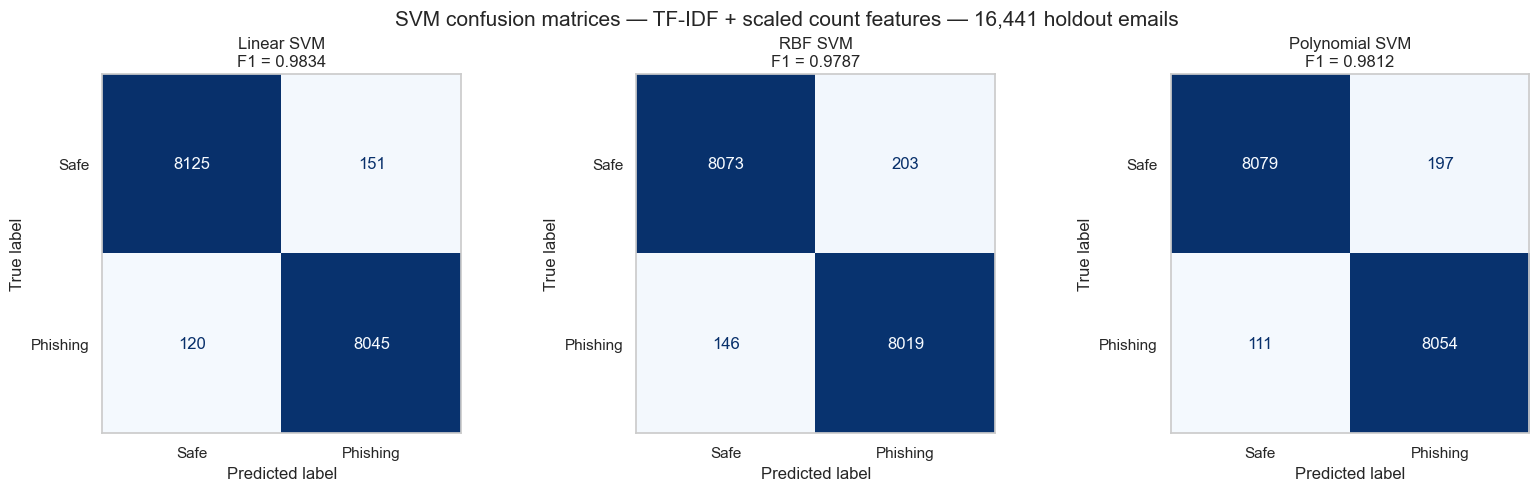

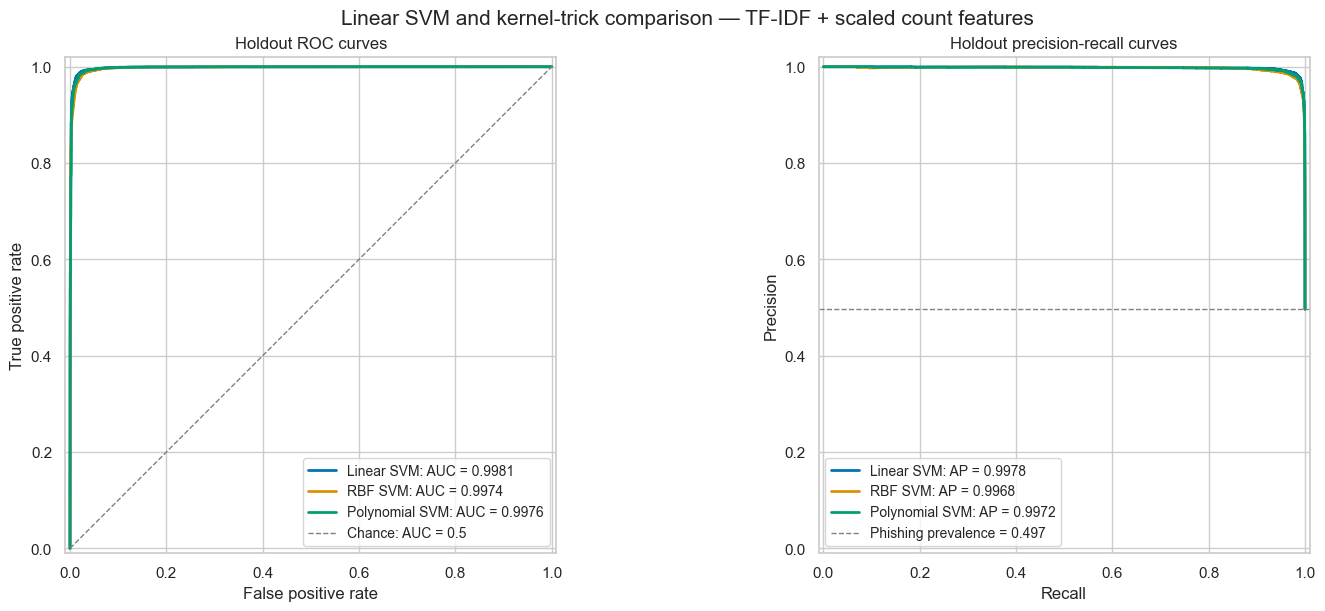

In [50]:
# Plot retained baseline results without refitting.
if RUN_FULL_SVM_COMPARISON and svm_holdout_results:
    # Use the same color scale for all confusion matrices.
    fig, axes = plt.subplots(1, len(svm_holdout_results), figsize=(16, 4.8),
                             constrained_layout=True, squeeze=False)
    shared_max = max(r['confusion_matrix'].max() for r in svm_holdout_results.values())
    for ax, (name, result) in zip(axes.flat, svm_holdout_results.items()):
        ConfusionMatrixDisplay(result['confusion_matrix'], display_labels=['Safe', 'Phishing']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d', im_kw={'vmin': 0, 'vmax': shared_max})
        ax.grid(False)
        ax.set_title(f"{name}\nF1 = {result['metrics']['f1']:.4f}")
    fig.suptitle(f'SVM confusion matrices — {svm_feature_set} — {len(y_test):,} holdout emails', fontsize=15)
    plt.show()

    # ROC and precision-recall curves use decision margins.
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
    colors = sns.color_palette('colorblind', len(svm_holdout_results))
    for color, (name, result) in zip(colors, svm_holdout_results.items()):
        RocCurveDisplay.from_predictions(
            y_test, result['decision_scores'], ax=axes[0], color=color, lw=2,
            label=f"{name}: AUC = {result['metrics']['roc_auc']:.4f}")
        PrecisionRecallDisplay.from_predictions(
            y_test, result['decision_scores'], ax=axes[1], color=color, lw=2,
            label=f"{name}: AP = {result['metrics']['average_precision']:.4f}")
    axes[0].plot([0, 1], [0, 1], '--', color='gray', lw=1, label='Chance: AUC = 0.5')
    prevalence = np.mean(y_test == 1)
    axes[1].axhline(prevalence, color='gray', linestyle='--', lw=1,
                    label=f'Phishing prevalence = {prevalence:.3f}')
    axes[0].set(title='Holdout ROC curves', xlabel='False positive rate', ylabel='True positive rate')
    axes[1].set(title='Holdout precision-recall curves', xlabel='Recall', ylabel='Precision')
    for ax, location in zip(axes, ['lower right', 'lower left']):
        ax.set(xlim=(-0.01, 1.01), ylim=(-0.01, 1.02))
        ax.legend(loc=location, fontsize=10)
    fig.suptitle(f'Linear SVM and kernel-trick comparison — {svm_feature_set}', fontsize=15)
    plt.show()


### Fixed-setting baseline summary

Summarize `svm_performance` and compare with Section 12 using the same features and holdout rows.


In [51]:
# Summarize baseline results when available.

if RUN_FULL_SVM_COMPARISON and not svm_performance.empty:
    print(f'Current run: {len(train_df):,} training emails; {len(test_df):,} holdout emails; '
          f'{svm_expected_feature_count:,} features '
          f'({X_train_tfidf.shape[1]:,} TF-IDF + {svm_count_feature_count} engineered counts).')
    print(f'NLTK source: {len(NLTK_STOP_WORDS)} words; effective stopwords: {len(EFFECTIVE_STOP_WORDS)}; '
          f'protected feature tokens: {len(PROTECTED_FEATURE_WORDS)}; overlap: 0.')
    for model_name, row in svm_performance.iterrows():
        print(f"{model_name}: accuracy {row['accuracy']:.2%}, F1 {row['f1']:.2%}, "
              f"ROC-AUC {row['roc_auc']:.6f}, false positives {int(row['false_positives'])}, "
              f"missed phishing {int(row['false_negatives'])}.")
    print('Fixed settings and default prediction rules were used for all three models.')


Current run: 65,635 training emails; 16,441 holdout emails; 5,006 features (5,000 TF-IDF + 6 engineered counts).
NLTK source: 198 words; effective stopwords: 172; protected feature tokens: 94; overlap: 0.
Linear SVM: accuracy 98.35%, F1 98.34%, ROC-AUC 0.998089, false positives 151, missed phishing 120.
RBF SVM: accuracy 97.88%, F1 97.87%, ROC-AUC 0.997351, false positives 203, missed phishing 146.
Polynomial SVM: accuracy 98.13%, F1 98.12%, ROC-AUC 0.997648, false positives 197, missed phishing 111.
Fixed settings and default prediction rules were used for all three models.


## 12. Fast GridSearchCV and reusable results DataFrames

Tune the Section 11 model families using three grouped training folds and the
same preprocessing. Select settings by mean validation phishing F1, then compare
baseline and tuned performance on the Dataset 3 holdout.

| Model | Quick grid | Candidates |
|---|---|---:|
| Linear SVM | `C=[0.1, 1, 10, 100]`, `class_weight=None` | 4 |
| RBF SVM | `C=[0.1, 1, 10, 100]`, `gamma='scale'` | 4 |
| Polynomial SVM | `C=[0.1, 1, 10, 100]`, `degree=3`, `gamma='scale'` | 4 |

**Flow:** 12 candidates → 36 CV fits → three full-training refits → holdout comparison.
TF-IDF and scaling fit within each fold. Each family has a separate temporary
preprocessing cache; models and results stay in memory. Up to four workers run in parallel.
CV fit times may include cache hits; full-pipeline refit times exclude evaluation.

**Controls:** edit `SVM_C_VALUES` or use `SVM_SEARCH_MODE='detailed'` for broader grids.
`SVM_COLLECT_TRAIN_SCORES=True` adds training metrics without extra fits.
`SVM_DISPLAY_COLUMNS` and row/model filters change presentation only.

| In-memory object | Contents |
|---|---|
| `svm_searches` | Fitted searches, best pipelines, parameters, and `cv_results_` |
| `svm_cv_results_df` | All candidates: training/validation means, fold standard deviations, timings, and F1 gaps |
| `svm_results_df` | Displayed candidate comparison |
| `svm_training_validation_df` | Eight training/validation metrics for each CV winner |
| `svm_holdout_results_df` | Selected models' holdout metrics and timings |
| `svm_tuning_effect_df` | Baseline versus tuned F1, RMSE, and missed phishing counts |

Training/CV RMSE are means of fold RMSE; test RMSE uses the holdout. RMSE uses binary
predictions, while ROC-AUC and AP use margins. Predictions retain the default threshold.
Restarting the kernel requires rerunning training. Full-corpus EDA and the length cap make the holdout comparison exploratory.


In [52]:
# Create unfitted templates using the shared TF-IDF and count settings.
svm_candidates = {
    'Linear SVM': create_linear_svm(
        tfidf_vectorizer, text_column=TEXT_COLUMN,
        count_columns=svm_count_columns, max_iter=50_000, random_state=RANDOM_STATE,
    ),
    'RBF SVM': create_kernel_svm(
        tfidf_vectorizer, kernel='rbf', text_column=TEXT_COLUMN,
        count_columns=svm_count_columns, random_state=RANDOM_STATE,
    ),
    'Polynomial SVM': create_kernel_svm(
        tfidf_vectorizer, kernel='poly', text_column=TEXT_COLUMN,
        count_columns=svm_count_columns, random_state=RANDOM_STATE,
    ),
}
svm_detailed_param_grids = {
    'Linear SVM': {'svm__C': [0.1, 1.0, 10.0], 'svm__class_weight': [None, 'balanced']},
    'RBF SVM': {'svm__C': [1.0, 10.0], 'svm__gamma': ['scale', 0.1, 1.0]},
    'Polynomial SVM': {'svm__C': [1.0, 10.0], 'svm__degree': [2, 3], 'svm__gamma': ['scale']},
}
# Quick mode varies C; detailed mode also varies kernel/class-weight settings.
SVM_SEARCH_MODE = 'quick'  # 'quick' or 'detailed'; edit grids below to experiment.
SVM_COLLECT_TRAIN_SCORES = True  # Record training metrics for each CV fold.
SVM_C_VALUES = [0.1, 1.0, 10.0, 100.0]  # Four regularization strengths per model.
SVM_POLYNOMIAL_DEGREE = 3  # Fixed in quick mode; detailed mode tests 2 and 3.
svm_quick_param_grids = {
    'Linear SVM': {'svm__C': SVM_C_VALUES, 'svm__class_weight': [None]},
    'RBF SVM': {'svm__C': SVM_C_VALUES, 'svm__gamma': ['scale']},
    'Polynomial SVM': {'svm__C': SVM_C_VALUES, 'svm__degree': [SVM_POLYNOMIAL_DEGREE], 'svm__gamma': ['scale']},
}
if SVM_SEARCH_MODE not in {'quick', 'detailed'}:
    raise ValueError("SVM_SEARCH_MODE must be 'quick' or 'detailed'.")
svm_param_grids = (svm_quick_param_grids if SVM_SEARCH_MODE == 'quick'
                  else svm_detailed_param_grids)
print('Search mode:', SVM_SEARCH_MODE)
print('Available SVM pipelines:', list(svm_candidates))
print('Feature set:', 'TF-IDF + scaled counts' if SVM_INCLUDE_COUNTS else 'TF-IDF only')

if SVM_INCLUDE_COUNTS:
    print('Additional features:', ', '.join(svm_count_columns))

# Report candidate and CV-fit counts before training.
svm_search_plan = pd.DataFrame([
    {'model': name, 'parameter_combinations': len(ParameterGrid(grid)),
     'CV folds': len(cv_splits), 'CV fits': len(ParameterGrid(grid)) * len(cv_splits)}
    for name, grid in svm_param_grids.items()
])
display(svm_search_plan)
print(f"Total: {svm_search_plan['CV fits'].sum()} CV fits plus one refit per model family.")


Search mode: quick
Available SVM pipelines: ['Linear SVM', 'RBF SVM', 'Polynomial SVM']
Feature set: TF-IDF + scaled counts
Additional features: total_word_count, urgency_terms_count, account_terms_count, threat_terms_count, financial_terms_count, official_terms_count


,model,parameter_combinations,CV folds,CV fits
0,Linear SVM,4,3,12
1,RBF SVM,4,3,12
2,Polynomial SVM,4,3,12


Total: 36 CV fits plus one refit per model family.


In [53]:
# Retain fitted searches in memory; cache preprocessing temporarily.

RUN_SVM_SEARCHES = True
SVM_MODELS_TO_RUN = ['Linear SVM', 'RBF SVM', 'Polynomial SVM']
SVM_SEARCH_JOBS = min(4, cpu_count())

svm_searches = {}
svm_comparison = pd.DataFrame()
selected_svm = None
selected_svm_name = None

if RUN_SVM_SEARCHES:
    with TemporaryDirectory(prefix='week5_svm_cv_') as cache_directory:
        # Limit each worker to one numerical-library thread.
        with parallel_config(backend='loky', inner_max_num_threads=1):
            for model_name in SVM_MODELS_TO_RUN:
                # Use a separate preprocessing cache for each family.
                filename = model_name.lower().replace(' ', '_')
                memory = Memory(Path(cache_directory) / filename, verbose=0)
                print(f'Tuning {model_name} on {len(train_df):,} training emails...', flush=True)
                candidate = clone(svm_candidates[model_name]).set_params(memory=memory)
                svm_searches[model_name] = tune_svm_model(
                    candidate, train_df, cv_splits,
                    svm_param_grids[model_name], target_column=TARGET_COLUMN,
                    n_jobs=SVM_SEARCH_JOBS, verbose=2,
                    return_train_score=SVM_COLLECT_TRAIN_SCORES,
                )
                search = svm_searches[model_name]
                # Detach temporary caches after fitting.
                search.best_estimator_.set_params(memory=None)
                search.estimator.set_params(memory=None)
                print(f'{model_name}: best CV F1 = {search.best_score_:.4f}; '
                      f'parameters = {search.best_params_}; '
                      f'elapsed = {search.elapsed_seconds_:.1f} seconds.', flush=True)

    svm_comparison = summarize_svm_searches(svm_searches)
    # Use template defaults as the CV reference when present in the grid.
    baseline_cv_f1 = {}
    for model_name, search in svm_searches.items():
        default_parameters = svm_candidates[model_name].get_params()
        baseline_index = next(
            (i for i, parameters in enumerate(search.cv_results_['params'])
             if all(default_parameters[key] == value for key, value in parameters.items())),
            None,
        )
        baseline_cv_f1[model_name] = (
            search.cv_results_['mean_test_f1'][baseline_index]
            if baseline_index is not None else np.nan
        )
    svm_comparison['baseline_cv_f1'] = svm_comparison['model'].map(baseline_cv_f1)
    svm_comparison['cv_f1_gain'] = svm_comparison['cv_f1'] - svm_comparison['baseline_cv_f1']
    # Select the family by validation F1.
    selected_svm_name = svm_comparison.iloc[0]['model']
    selected_svm = svm_searches[selected_svm_name].best_estimator_
    print('Selected using training CV:', selected_svm_name, flush=True)
    print('Selected parameters:', svm_searches[selected_svm_name].best_params_, flush=True)
else:
    print('SVM methods are ready. Set RUN_SVM_SEARCHES=True to train and tune.')


Tuning Linear SVM on 65,635 training emails...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END .................svm__C=0.1, svm__class_weight=None; total time=  29.0s
[CV] END .................svm__C=0.1, svm__class_weight=None; total time=  30.0s
[CV] END .................svm__C=0.1, svm__class_weight=None; total time=  28.1s
[CV] END .................svm__C=1.0, svm__class_weight=None; total time=  31.2s
[CV] END .................svm__C=1.0, svm__class_weight=None; total time=  12.4s
[CV] END ................svm__C=10.0, svm__class_weight=None; total time=  13.1s
[CV] END ................svm__C=10.0, svm__class_weight=None; total time=  14.0s
[CV] END .................svm__C=1.0, svm__class_weight=None; total time=  20.2s
[CV] END ................svm__C=10.0, svm__class_weight=None; total time=  10.1s
[CV] END ...............svm__C=100.0, svm__class_weight=None; total time=   9.9s
[CV] END ...............svm__C=100.0, svm__class_weight=None; total time=   9.6s
[C

### Collect CV results for every parameter combination

I collected all **12 configurations** from the fitted searches' `cv_results_` into in-memory tables, with training scores enabled through `SVM_COLLECT_TRAIN_SCORES=True`.

- `Training_F1` and `CV_Avg_F1score`: mean training and validation F1 across the three folds.
- `F1_Gap`: training F1 minus validation F1, calculated before rounding.
- `CV Avg Precision`: mean validation precision for phishing, distinct from average precision (AP).
- `CV Fit time`: mean fold-fit seconds, potentially including preprocessing cache hits.

I selected each family's best configuration and the overall winner using **mean validation F1**.


In [54]:
# Collect fold-training and validation metrics; select by validation F1.
metric_names = {
    'accuracy': 'Accuracy', 'balanced_accuracy': 'Balanced_Accuracy',
    'precision': 'Precision', 'recall': 'Recall', 'f1': 'F1',
    'roc_auc': 'ROC_AUC', 'average_precision': 'Average_precision', 'rmse': 'RMSE',
}
svm_cv_frames = {}
svm_cv_result_tables = {}
svm_best_candidate_ids = {}

for model_name in SVM_MODELS_TO_RUN:
    results = pd.DataFrame(svm_searches[model_name].cv_results_)
    assert results['params'].tolist() == list(ParameterGrid(svm_param_grids[model_name]))
    svm_cv_frames[model_name] = results
    svm_best_candidate_ids[model_name] = int(results['mean_test_f1'].idxmax())

    table = pd.DataFrame({
        'Model': model_name, 'Candidate': results.index, 'Parameters': results['params'],
        'CV_Mean_Fit_Time_Seconds': results['mean_fit_time'],
        'CV_Std_Fit_Time_Seconds': results['std_fit_time'],
    })
    for metric, column in metric_names.items():
        sign = -1 if metric == 'rmse' else 1  # Show negative-loss RMSE as positive.
        for split, prefix in [('train', 'Training'), ('test', 'CV')]:
            table[f'{prefix}_{column}'] = sign * results.get(f'mean_{split}_{metric}', np.nan)
            table[f'{prefix}_{column}_Std'] = results.get(f'std_{split}_{metric}', np.nan)
    table['F1_Gap'] = table['Training_F1'] - table['CV_F1']
    table['Selected_by_CV'] = table['Candidate'].eq(svm_best_candidate_ids[model_name])
    svm_cv_result_tables[model_name] = table

# Combine candidate metrics and select by validation F1.
svm_cv_results_df = pd.concat(svm_cv_result_tables.values(), ignore_index=True)
svm_parameter_results = svm_cv_results_df
selected_svm_name = svm_cv_results_df.loc[svm_cv_results_df['CV_F1'].idxmax(), 'Model']
if svm_cv_results_df['Training_F1'].isna().all():
    print('Training scores are unavailable. Enable SVM_COLLECT_TRAIN_SCORES and rerun the searches.')

# Select and label display columns; CV Avg Precision uses precision_score.
display_columns = {
    'Model': 'model', 'Parameters': 'hyper param',
    'CV_RMSE': 'CV_rmse', 'CV_ROC_AUC': 'CV_ROC_AUC',
    'CV_Precision': 'CV Avg Precision', 'CV_Recall': 'CV_Avg_recall',
    'CV_F1': 'CV_Avg_F1score', 'CV_Mean_Fit_Time_Seconds': 'CV Fit time',
    'Training_F1': 'Training_F1', 'F1_Gap': 'F1_Gap',
}
svm_results_df = svm_cv_results_df[list(display_columns)].rename(columns=display_columns)
svm_results_df['hyper param'] = svm_results_df['hyper param'].map(
    lambda params: {key.removeprefix('svm__'): value for key, value in params.items()}
)


### Retain holdout performance for the selected models

Evaluate each search's refitted `best_estimator_` on `test_df` without retraining.
Keep holdout metrics in `svm_holdout_results_df` and reports/predictions in
`svm_tuned_holdout_results`; CV metrics remain in `svm_results_df`.


In [55]:
# Evaluate each CV-selected pipeline on the holdout without refitting.
svm_tuned_models = {}
svm_tuned_holdout_results = {}
performance_records = []
for model_name in SVM_MODELS_TO_RUN:
    search = svm_searches[model_name]
    model = search.best_estimator_
    assert model.named_steps['svm'].n_features_in_ == X_train_augmented.shape[1]
    start = time.perf_counter()
    result = evaluate_svm_model(model, test_df, target_column=TARGET_COLUMN,
                                name=model_name, plot=False)
    evaluation_seconds = time.perf_counter() - start
    svm_tuned_models[model_name] = model
    svm_tuned_holdout_results[model_name] = result
    metrics = result['metrics']
    best = search.best_index_
    scores = search.cv_results_
    # Matrix order is [[TN, FP], [FN, TP]]; FN counts missed phishing.
    tn, fp, fn, tp = result['confusion_matrix'].ravel()
    performance_records.append({
        'Model': model_name, 'Candidate': best, 'Parameters': search.best_params_,
        'CV_RMSE': -scores['mean_test_rmse'][best], 'Test_RMSE': metrics['rmse'],
        'ROC_AUC': metrics['roc_auc'], 'Average_precision': metrics['average_precision'],
        'Precision': metrics['precision'], 'Recall': metrics['recall'], 'F1': metrics['f1'],
        'Fit_Time_Seconds': search.refit_time_,
        'CV_F1': scores['mean_test_f1'][best], 'CV_F1_Std': scores['std_test_f1'][best],
        'CV_RMSE_Std': scores['std_test_rmse'][best],
        'CV_ROC_AUC': scores['mean_test_roc_auc'][best],
        'CV_Average_precision': scores['mean_test_average_precision'][best],
        'CV_Precision': scores['mean_test_precision'][best],
        'CV_Recall': scores['mean_test_recall'][best],
        'CV_Mean_Fit_Time_Seconds': scores['mean_fit_time'][best],
        'CV_Std_Fit_Time_Seconds': scores['std_fit_time'][best],
        'Search_Time_Seconds': search.elapsed_seconds_,
        'Evaluation_Time_Seconds': evaluation_seconds,
        'Accuracy': metrics['accuracy'], 'Balanced_Accuracy': metrics['balanced_accuracy'],
        'Test_Error_Rate': metrics['error_rate'], 'Selected_by_CV': True,
        'Features': X_train_augmented.shape[1], 'Training_Rows': len(train_df), 'Test_Rows': len(test_df),
        'True_Negatives': int(tn), 'False_Positives': int(fp),
        'False_Negatives': int(fn), 'True_Positives': int(tp),
    })

# Retain full-precision metrics and the CV-selected model.
svm_holdout_results_df = pd.DataFrame(performance_records).sort_values('CV_F1', ascending=False).reset_index(drop=True)
svm_best_method_results = svm_holdout_results_df.copy()  # Reusable comparison alias.
selected_svm = svm_tuned_models[selected_svm_name]
svm_holdout_result = svm_tuned_holdout_results[selected_svm_name]


### Candidate results and training-versus-validation metrics

Display all candidates, then each CV winner's training/validation fold means:
accuracy, balanced accuracy, precision, recall, F1, ROC-AUC, AP, and RMSE.
`svm_training_validation_df` retains this comparison; display filters never change selection.
If training scores are missing, rerun Sections 10 and 12 with `SVM_COLLECT_TRAIN_SCORES=True`.


In [56]:
# Filter and round display copies; retain full results for selection.
SVM_DISPLAY_COLUMNS = [
    'model', 'hyper param', 'CV_rmse', 'CV_ROC_AUC', 'CV Avg Precision',
    'CV_Avg_recall', 'CV_Avg_F1score', 'CV Fit time', 'Training_F1', 'F1_Gap',
]
SVM_DISPLAY_MODELS = None  # Example: ['Linear SVM', 'RBF SVM']; None shows all.
SVM_DISPLAY_SORT_BY = ['model', 'CV_Avg_F1score']
SVM_DISPLAY_ASCENDING = [True, False]
SVM_DISPLAY_TOP_N = None  # None displays every tested configuration.

svm_display_df = svm_results_df.copy()
if SVM_DISPLAY_MODELS is not None:
    svm_display_df = svm_display_df[svm_display_df['model'].isin(SVM_DISPLAY_MODELS)]
svm_display_df = svm_display_df.sort_values(SVM_DISPLAY_SORT_BY, ascending=SVM_DISPLAY_ASCENDING)
if SVM_DISPLAY_TOP_N is not None:
    svm_display_df = svm_display_df.head(SVM_DISPLAY_TOP_N)
with pd.option_context('display.max_columns', None, 'display.max_colwidth', None):
    display(svm_display_df.loc[:, SVM_DISPLAY_COLUMNS].round(4))

# Compare training/validation fold means for each CV winner.
svm_metric_columns = ['Accuracy', 'Balanced_Accuracy', 'Precision', 'Recall',
                      'F1', 'ROC_AUC', 'Average_precision', 'RMSE']
svm_training_validation_df = pd.DataFrame([
    {'Model': row['Model'], 'Dataset': dataset,
     **{metric: row[f'{prefix}_{metric}'] for metric in svm_metric_columns}}
    for _, row in svm_cv_results_df.loc[svm_cv_results_df['Selected_by_CV']].iterrows()
    for prefix, dataset in [('Training', 'Training folds'), ('CV', 'Validation folds')]
])
print('Training vs validation: mean fold metrics for each CV-selected model')
if svm_training_validation_df[svm_metric_columns].isna().any().any():
    print('Missing scores: rerun Sections 10 and 12 with SVM_COLLECT_TRAIN_SCORES=True.')
with pd.option_context('display.max_columns', None):
    display(svm_training_validation_df.round(4))

# Report each family's best validation-F1 setting.
svm_best_configurations = {}
print('Best configuration for each classifier (highest mean CV phishing F1):')
for model_name in SVM_MODELS_TO_RUN:
    model_rows = svm_results_df[svm_results_df['model'].eq(model_name)]
    # Select from all unrounded candidates.
    best_row = model_rows.loc[model_rows['CV_Avg_F1score'].idxmax()]
    svm_best_configurations[model_name] = {
        'hyper param': best_row['hyper param'],
        'CV_Avg_F1score': float(best_row['CV_Avg_F1score']),
        'CV_ROC_AUC': float(best_row['CV_ROC_AUC']),
    }
    parameter_text = ', '.join(f'{key}={value}' for key, value in best_row['hyper param'].items())
    print(f"  {model_name}: {parameter_text}; "
          f"CV F1={best_row['CV_Avg_F1score']:.6f}, CV ROC-AUC={best_row['CV_ROC_AUC']:.6f}")


,model,hyper param,CV_rmse,CV_ROC_AUC,CV Avg Precision,CV_Avg_recall,CV_Avg_F1score,CV Fit time,Training_F1,F1_Gap
1,Linear SVM,"{'C': 1.0, 'class_weight': None}",0.1399,0.9978,0.9780,0.9850,0.9814,12.9351,0.9953,0.0139
0,Linear SVM,"{'C': 0.1, 'class_weight': None}",0.1420,0.9977,0.9776,0.9844,0.9810,20.9256,0.9868,0.0058
2,Linear SVM,"{'C': 10.0, 'class_weight': None}",0.1550,0.9964,0.9743,0.9803,0.9773,4.3049,0.9995,0.0222
3,Linear SVM,"{'C': 100.0, 'class_weight': None}",0.1654,0.9950,0.9720,0.9762,0.9741,2.7299,0.9999,0.0258
9,Polynomial SVM,"{'C': 1.0, 'degree': 3, 'gamma': 'scale'}",0.1300,0.9979,0.9805,0.9876,0.9840,215.1813,0.9908,0.0068
10,Polynomial SVM,"{'C': 10.0, 'degree': 3, 'gamma': 'scale'}",0.1345,0.9978,0.9804,0.9854,0.9829,243.5962,0.9981,0.0152
11,Polynomial SVM,"{'C': 100.0, 'degree': 3, 'gamma': 'scale'}",0.1446,0.9970,0.9774,0.9830,0.9802,250.3370,0.9999,0.0197
8,Polynomial SVM,"{'C': 0.1, 'degree': 3, 'gamma': 'scale'}",0.1826,0.9948,0.9588,0.9789,0.9687,325.1091,0.9729,0.0042
6,RBF SVM,"{'C': 10.0, 'gamma': 'scale'}",0.1225,0.9983,0.9844,0.9872,0.9858,357.2045,0.9949,0.0090
7,RBF SVM,"{'C': 100.0, 'gamma': 'scale'}",0.1329,0.9980,0.9811,0.9854,0.9832,359.8511,0.9997,0.0165


Training vs validation: mean fold metrics for each CV-selected model


,Model,Dataset,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,Average_precision,RMSE
0,Linear SVM,Training folds,0.9951,0.9950,0.9941,0.9965,0.9953,0.9998,0.9998,0.0702
1,Linear SVM,Validation folds,0.9803,0.9801,0.9780,0.9850,0.9814,0.9978,0.9979,0.1399
2,RBF SVM,Training folds,0.9946,0.9945,0.9939,0.9958,0.9949,0.9996,0.9996,0.0738
3,RBF SVM,Validation folds,0.9850,0.9849,0.9844,0.9872,0.9858,0.9983,0.9983,0.1225
4,Polynomial SVM,Training folds,0.9903,0.9901,0.9882,0.9934,0.9908,0.9992,0.9992,0.0987
5,Polynomial SVM,Validation folds,0.9831,0.9828,0.9805,0.9876,0.9840,0.9979,0.9980,0.1300


Best configuration for each classifier (highest mean CV phishing F1):
  Linear SVM: C=1.0, class_weight=None; CV F1=0.981447, CV ROC-AUC=0.997765
  RBF SVM: C=10.0, gamma=scale; CV F1=0.985805, CV ROC-AUC=0.998342
  Polynomial SVM: C=1.0, degree=3, gamma=scale; CV F1=0.984027, CV ROC-AUC=0.997892


### Findings: the 12-configuration SVM comparison

I found that RBF SVM with C=10 and gamma=scale performed best among the tested configurations. It achieved validation F1 of 0.9858, holdout F1 of 0.9856, and 98.56% holdout accuracy.
Tuning reduced RBF’s holdout errors from 349 to 236, including 45 fewer missed phishing emails. Linear SVM retained C=1 and showed no improvement. Increasing C to 100 raised training scores but reduced validation performance across all three families, indicating overfitting.
RBF’s stronger performance required substantially more fitting time than linear SVM. I selected it using validation F1 and used the holdout to assess that choice. The close validation and holdout scores supported consistent performance on Dataset 3, although full-corpus preprocessing and EDA meant the comparison remained exploratory.

I tested **C = 0.1, 1, 10, and 100** for each SVM family using three grouped folds: **12 configurations and 36 CV fits**, followed by one refit per family. Both kernels used `gamma=scale`; polynomial degree remained fixed at 3.

| Model | Selected C | Training F1 | Validation F1 | F1 gap | CV RMSE | Mean CV fit (s) |
|---|---:|---:|---:|---:|---:|---:|
| Linear | 1 | 0.9953 | 0.9814 | 0.0139 | 0.1399 | 12.94 |
| RBF | 10 | 0.9949 | 0.9858 | 0.0090 | 0.1225 | 357.20 |
| Polynomial | 1 | 0.9908 | 0.9840 | 0.0068 | 0.1300 | 215.18 |

Training and validation scores were fold means; F1 gaps were calculated before rounding.

- **Overall selection:** I selected **RBF with C=10** using the highest validation F1 (**0.985805**). It also achieved the lowest CV RMSE (**0.1225**) and highest CV ROC-AUC (**0.998342**). Its validation precision and recall were **0.9844** and **0.9872**. Polynomial had slightly higher recall (**0.9876**), but lower F1.
- **Linear trade-off:** C=0.1 nearly matched C=1 in validation F1 (**0.9810 versus 0.9814**) with a smaller gap (**0.0058 versus 0.0139**). I retained C=1 because selection used validation F1, not the smallest gap.
- **Underfitting and overfitting:** RBF at C=0.1 had low training and validation F1 (**0.9157 and 0.9128**), suggesting underfitting despite its small gap. At C=100, all three families approached perfect training F1 while validation F1 fell below their selected settings. Their gaps widened to **0.0258 linear, 0.0165 RBF, and 0.0197 polynomial**.
- **Fit-time trade-off:** Linear fitted much faster than either kernel model. The timings above measured mean CV fold-fit time, not total search or full-training refit time, and could include preprocessing cache hits.

These were the best settings within the tested grid; I did not tune gamma or polynomial degree in this quick search. Holdout results were excluded from model selection.


### Compare error, fit time, and classification performance

Compare selected models' fold-training, validation, and holdout RMSE alongside
full-training refit times. Confusion matrices and ROC/precision-recall curves
reuse the same holdout predictions and margins.


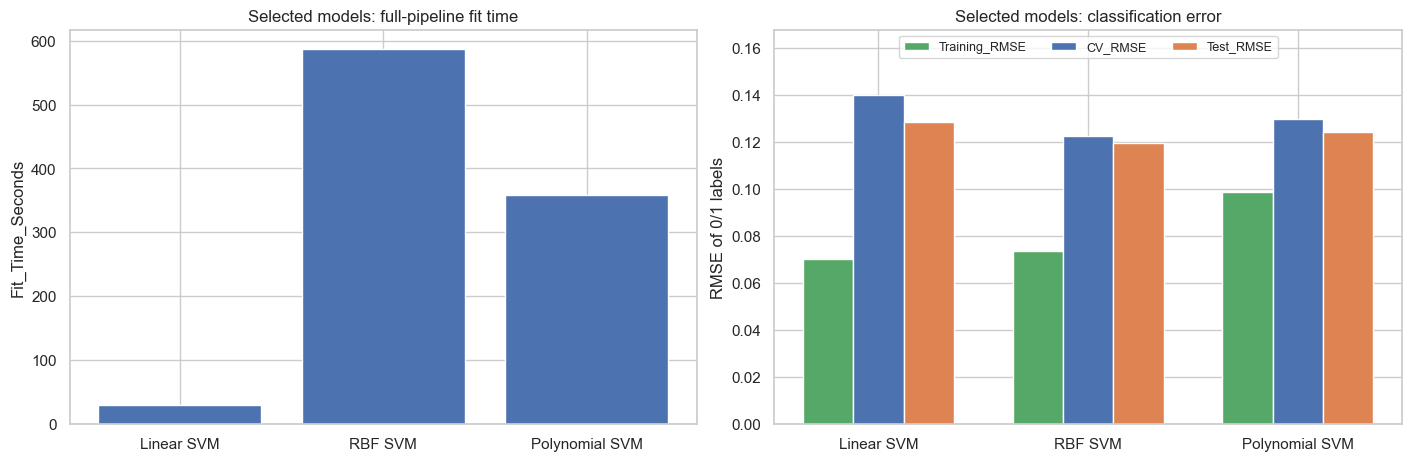

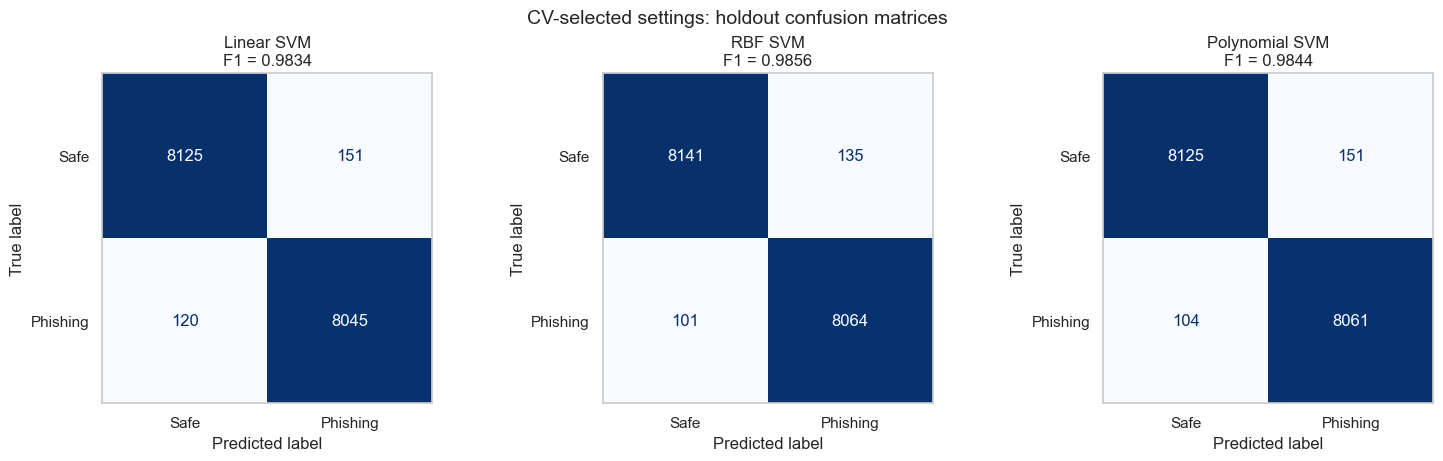

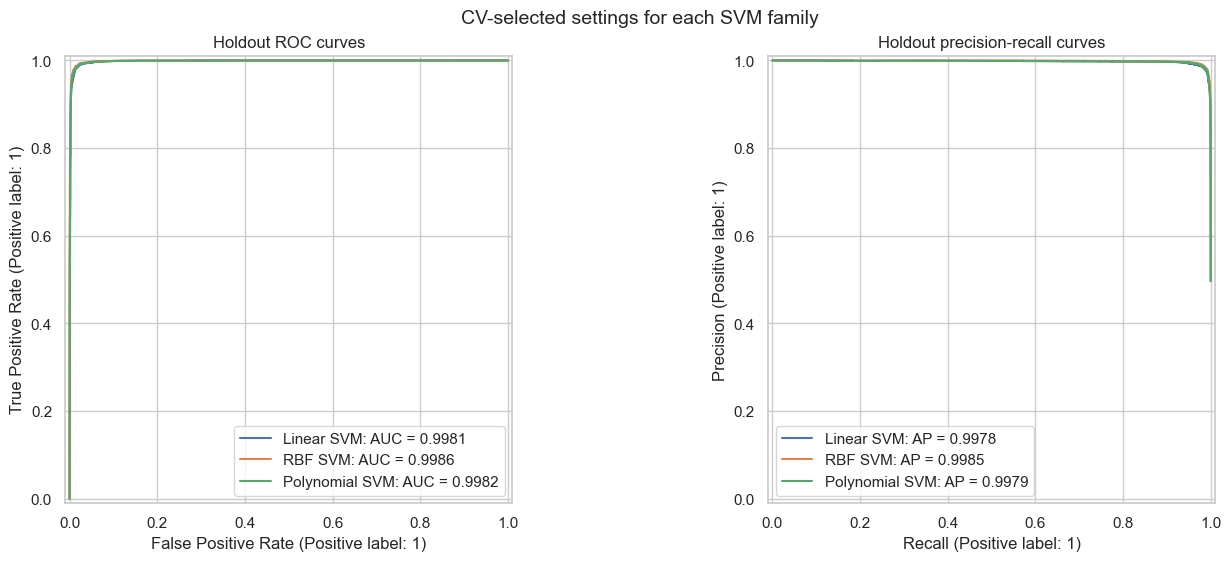

In [57]:
# Plot CV winners using retained metrics, predictions, and margins.

if not svm_holdout_results_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
    chart = svm_holdout_results_df.set_index('Model').loc[SVM_MODELS_TO_RUN]
    positions = np.arange(len(chart))
    axes[0].bar(positions, chart['Fit_Time_Seconds'])
    axes[0].set(title='Selected models: full-pipeline fit time', ylabel='Fit_Time_Seconds')
    # Training RMSE averages each fold's training RMSE.
    chart['Training_RMSE'] = (svm_cv_results_df.loc[svm_cv_results_df['Selected_by_CV']]
                              .set_index('Model')['Training_RMSE'].reindex(chart.index))
    if chart['Training_RMSE'].isna().any():
        print('Training RMSE is missing; rerun Sections 10 and 12 with SVM_COLLECT_TRAIN_SCORES=True.')
    width = 0.24
    axes[1].bar(positions - width, chart['Training_RMSE'], width=width, color='C2', label='Training_RMSE')
    axes[1].bar(positions, chart['CV_RMSE'], width=width, color='C0', label='CV_RMSE')
    axes[1].bar(positions + width, chart['Test_RMSE'], width=width, color='C1', label='Test_RMSE')
    axes[1].set(title='Selected models: classification error', ylabel='RMSE of 0/1 labels')
    axes[1].margins(y=0.2)
    axes[1].legend(loc='upper center', ncol=3, fontsize=9)
    for ax in axes:
        ax.set_xticks(positions, chart.index)
    plt.show()

    # Plot holdout predictions at the default decision threshold.
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
    for ax, name in zip(axes, SVM_MODELS_TO_RUN):
        result = svm_tuned_holdout_results[name]
        ConfusionMatrixDisplay(result['confusion_matrix'], display_labels=['Safe', 'Phishing']).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='d')
        ax.grid(False)
        ax.set_title(f"{name}\nF1 = {result['metrics']['f1']:.4f}")
    fig.suptitle('CV-selected settings: holdout confusion matrices', fontsize=14)
    plt.show()

    # ROC-AUC and AP summarize rankings from decision margins.
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    for name in SVM_MODELS_TO_RUN:
        result = svm_tuned_holdout_results[name]
        RocCurveDisplay.from_predictions(y_test, result['decision_scores'], ax=axes[0], name=name)
        PrecisionRecallDisplay.from_predictions(y_test, result['decision_scores'], ax=axes[1], name=name)
    axes[0].legend([f"{name}: AUC = {svm_tuned_holdout_results[name]['metrics']['roc_auc']:.4f}" for name in SVM_MODELS_TO_RUN], loc='lower right')
    axes[1].legend([f"{name}: AP = {svm_tuned_holdout_results[name]['metrics']['average_precision']:.4f}" for name in SVM_MODELS_TO_RUN], loc='lower left')
    axes[0].set_title('Holdout ROC curves')
    axes[1].set_title('Holdout precision-recall curves')
    fig.suptitle('CV-selected settings for each SVM family', fontsize=14)
    plt.show()


### Findings: accuracy and classification performance on the holdout

I evaluated the three CV-selected models on the same **16,441 emails: 8,276 Safe and 8,165 Phishing**. Precision, recall, F1, and average precision (AP) referred to the Phishing class.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | AP |
|---|---:|---:|---:|---:|---:|---:|
| Linear (C=1) | 98.35% | 98.16% | 98.53% | 0.9834 | 0.9981 | 0.9978 |
| RBF (C=10) | 98.56% | 98.35% | 98.76% | 0.9856 | 0.9986 | 0.9985 |
| Polynomial (C=1, degree=3) | 98.45% | 98.16% | 98.73% | 0.9844 | 0.9982 | 0.9979 |

The confusion matrices showed the remaining classification errors:

| Model | False positives | Missed phishing | Total errors | Holdout RMSE |
|---|---:|---:|---:|---:|
| Linear | 151 | 120 | 271 | 0.1284 |
| RBF | 135 | 101 | 236 | 0.1198 |
| Polynomial | 151 | 104 | 255 | 0.1245 |

**RBF performed best across these holdout metrics**, with **35 fewer errors than linear** and **19 fewer than polynomial**. It produced both the fewest false alarms and the fewest missed phishing emails. Polynomial missed **16 fewer phishing emails than linear**, while both flagged **151 Safe emails** incorrectly.

The high ROC-AUC and AP values indicated strong ranking performance, but the best model still missed **101 phishing emails**. Its holdout F1 (**0.9856**) closely matched its validation F1 (**0.985805**), supporting consistent performance on this dataset.

I retained **RBF with C=10 and gamma=scale** because it had already achieved the highest training-CV F1; I did not use the holdout to change the selected model. Predictions used the standard estimator rule without threshold tuning. Full-corpus EDA and the length-cap calculation kept this holdout comparison exploratory.


### Effect of tuning: baseline versus selected models

Compare Section 11 baselines with Section 12 CV winners on the same holdout/features.
Positive `F1_gain` and `Fewer_missed`, and lower RMSE, indicate improvement.
Selection remains based on validation F1.


In [58]:
# Compare retained baseline and tuned holdout metrics.
svm_tuning_effect_df = pd.DataFrame()
if RUN_FULL_SVM_COMPARISON and not svm_performance.empty and not svm_holdout_results_df.empty:
    baseline = svm_performance.loc[SVM_MODELS_TO_RUN]
    tuned = svm_holdout_results_df.set_index('Model').loc[SVM_MODELS_TO_RUN]
    assert np.array_equal(baseline['features'], tuned['Features'])
    assert np.array_equal(baseline['training_rows'], tuned['Training_Rows'])
    assert np.array_equal(baseline['rows'], tuned['Test_Rows'])
    svm_tuning_effect_df = pd.DataFrame({
        'Baseline_F1': baseline['f1'], 'Tuned_F1': tuned['F1'],
        'F1_gain': tuned['F1'] - baseline['f1'],
        'Baseline_RMSE': baseline['rmse'], 'Tuned_RMSE': tuned['Test_RMSE'],
        'Baseline_missed': baseline['false_negatives'],
        'Tuned_missed': tuned['False_Negatives'],
        'Fewer_missed': baseline['false_negatives'] - tuned['False_Negatives'],
    }).rename_axis('Model')
    with pd.option_context('display.max_columns', None):
        display(svm_tuning_effect_df.round(4))
else:
    print('Run the baseline and tuning sections to compare their holdout results.')


,Baseline_F1,Tuned_F1,F1_gain,Baseline_RMSE,Tuned_RMSE,Baseline_missed,Tuned_missed,Fewer_missed
Model,,,,,,,,
Linear SVM,0.9834,0.9834,0.0000,0.1284,0.1284,120,120,0
RBF SVM,0.9787,0.9856,0.0069,0.1457,0.1198,146,101,45
Polynomial SVM,0.9812,0.9844,0.0032,0.1369,0.1245,111,104,7


#### Observation: the effect of tuning

Use `svm_tuning_effect_df` from Dataset 3 to report changes in F1, RMSE, and missed
phishing emails. Improvements must come from the new results, not the Dataset 1 run.
Polynomial baseline degree is 2; quick tuning fixes degree at 3, so both C and degree can differ.


## 13. Hyperparameter graphs — final comparison

Plot candidate metrics from `svm_cv_frames`: blue dashed lines show training scores,
red solid lines show validation scores, bars show mean CV fit time, and stars mark
CV-F1 winners. Error bars show fold standard deviations, not confidence intervals.

Plots reuse in-memory results. If training curves are missing, rerun Sections 10
and 12 with `SVM_COLLECT_TRAIN_SCORES=True`, then this section.


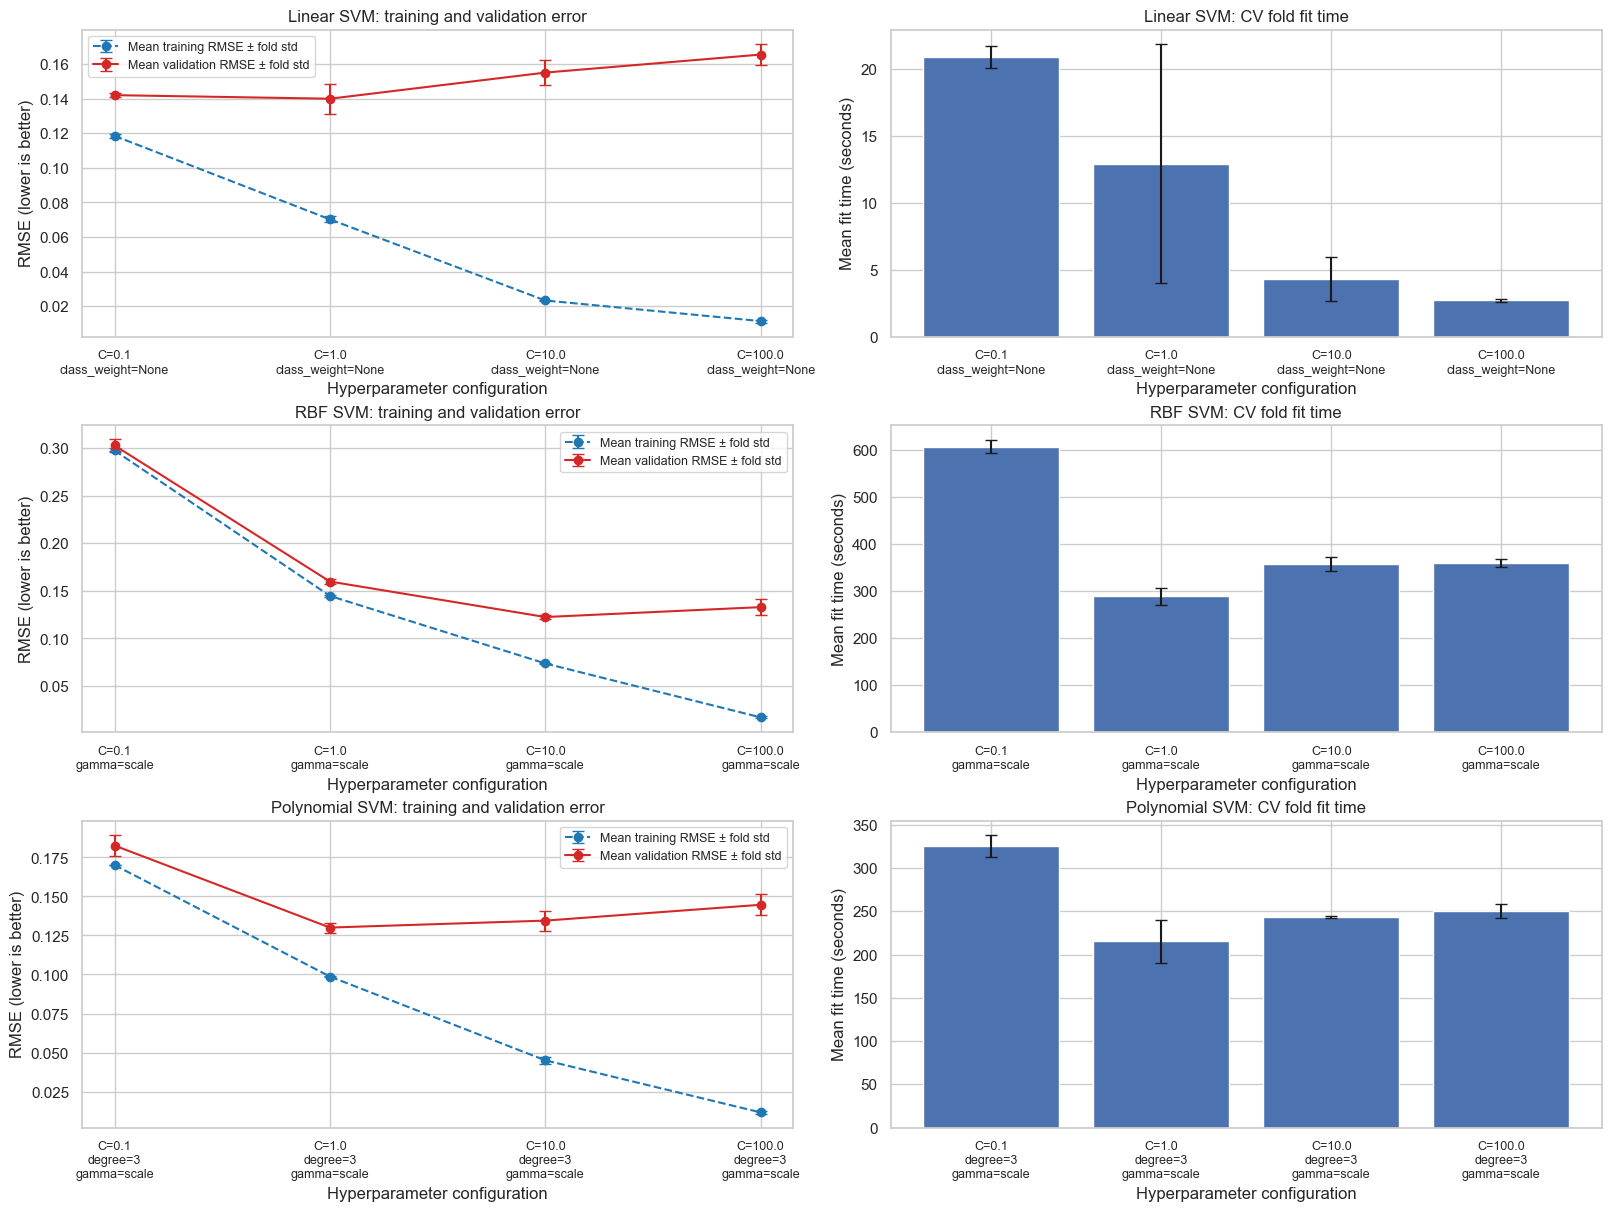

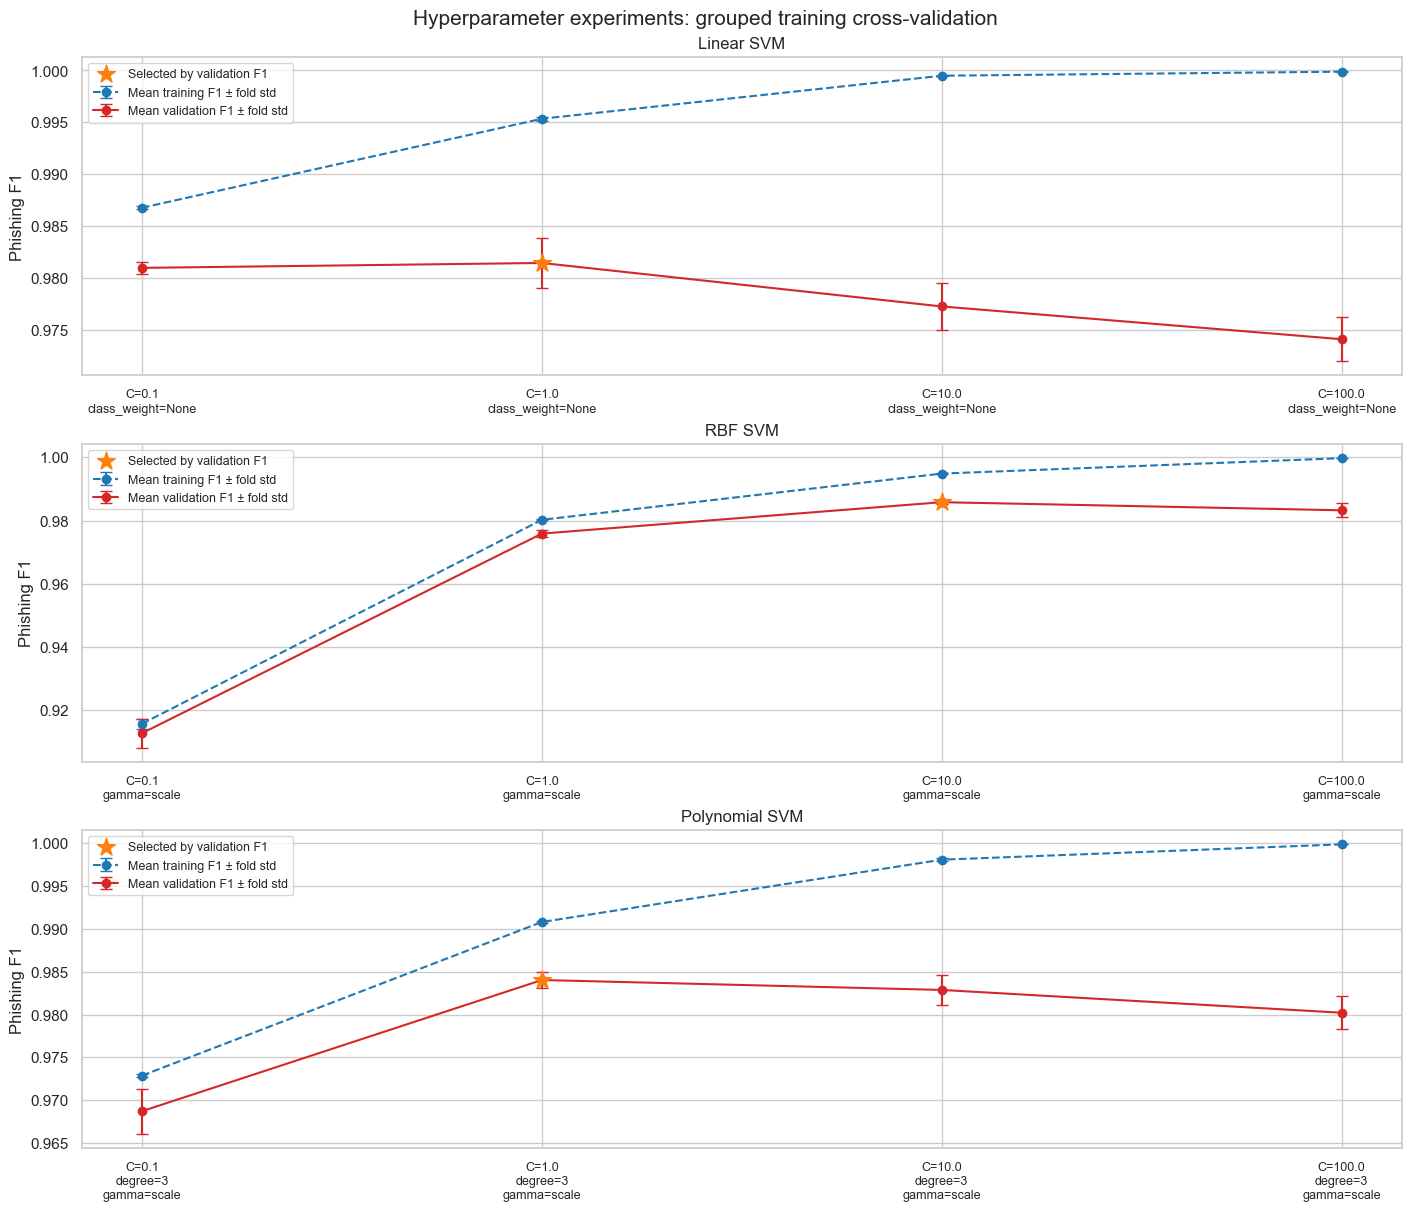

In [59]:
# Plot retained candidate scores; error bars show fold standard deviations.
missing_training_models = [
    name for name, results in svm_cv_frames.items()
    if any(f'mean_train_{metric}' not in results or results[f'mean_train_{metric}'].isna().any()
           for metric in ('f1', 'rmse'))
]
if missing_training_models:
    print('Training curves unavailable for: ' + ', '.join(missing_training_models)
          + '. Rerun Sections 10 and 12 with SVM_COLLECT_TRAIN_SCORES=True, then this cell.')

fig, axes = plt.subplots(len(svm_cv_frames), 2, figsize=(16, 4 * len(svm_cv_frames)),
                         constrained_layout=True, squeeze=False)
for row, (model_name, results) in enumerate(svm_cv_frames.items()):
    positions = np.arange(len(results))
    if 'mean_train_rmse' in results:
        axes[row, 0].errorbar(positions, -results['mean_train_rmse'], yerr=results['std_train_rmse'],
                             fmt='o--', capsize=4, color='tab:blue', label='Mean training RMSE ± fold std')
    axes[row, 0].errorbar(positions, -results['mean_test_rmse'], yerr=results['std_test_rmse'],
                         fmt='o-', capsize=4, color='tab:red', label='Mean validation RMSE ± fold std')
    axes[row, 0].legend(loc='best', fontsize=9)
    axes[row, 1].bar(positions, results['mean_fit_time'], yerr=results['std_fit_time'], capsize=4)
    axes[row, 0].set(title=f'{model_name}: training and validation error', ylabel='RMSE (lower is better)')
    axes[row, 1].set(title=f'{model_name}: CV fold fit time', ylabel='Mean fit time (seconds)', ylim=(0, None))
    for ax in axes[row]:
        labels = ['\n'.join(f"{key.removeprefix('svm__')}={value}" for key, value in parameters.items())
                  for parameters in results['params']]
        ax.set_xticks(positions, labels, fontsize=9)
        ax.set_xlabel('Hyperparameter configuration')
plt.show()

fig, axes = plt.subplots(len(svm_cv_frames), 1, figsize=(14, 4 * len(svm_cv_frames)),
                         constrained_layout=True, squeeze=False)
for ax, (model_name, results) in zip(axes.flat, svm_cv_frames.items()):
    positions = np.arange(len(results))
    labels = ['\n'.join(f"{key.removeprefix('svm__')}={value}" for key, value in params.items())
              for params in results['params']]
    if 'mean_train_f1' in results:
        ax.errorbar(positions, results['mean_train_f1'], yerr=results['std_train_f1'], fmt='o--',
                    capsize=4, color='tab:blue', label='Mean training F1 ± fold std')
    ax.errorbar(positions, results['mean_test_f1'], yerr=results['std_test_f1'], fmt='o-',
                capsize=4, color='tab:red', label='Mean validation F1 ± fold std')
    # Mark the candidate selected by validation F1.
    best = svm_best_candidate_ids[model_name]
    ax.scatter(best, results.loc[best, 'mean_test_f1'], marker='*', s=180, color='tab:orange',
               zorder=5, label='Selected by validation F1')
    ax.set_xticks(positions, labels, fontsize=9)
    ax.set(title=model_name, ylabel='Phishing F1')
    ax.legend(loc='best', fontsize=9)
fig.suptitle('Hyperparameter experiments: grouped training cross-validation', fontsize=15)
plt.show()


## 14. Observation on hyperparameter tuning and classification performance

I compared **12 configurations using three grouped CV folds** on **65,635 training emails** with **5,000 TF-IDF features and six counts**. I selected **RBF SVM (C=10, gamma=scale)** because it had the highest mean validation phishing F1 (**0.985805**).

| Model | Selected settings | Training F1 | Validation F1 | F1 gap | Holdout F1 |
|---|---|---:|---:|---:|---:|
| Linear | C=1 | 0.9953 | 0.9814 | 0.0139 | 0.9834 |
| RBF | C=10, gamma=scale | 0.9949 | 0.9858 | 0.0090 | 0.9856 |
| Polynomial | C=1, degree=3, gamma=scale | 0.9908 | 0.9840 | 0.0068 | 0.9844 |

Training and validation scores were fold means; gaps were calculated before rounding. All models used `class_weight=None`; polynomial used `coef0=1`. Increasing C to 100 raised training F1 close to 1 but reduced validation F1 in every family, indicating overfitting at weaker regularization.

I evaluated the selected models on the same **16,441 holdout emails** (8,276 Safe; 8,165 Phishing):

| Model | Accuracy | False positives | Missed phishing | Total errors |
|---|---:|---:|---:|---:|
| Linear | 98.35% | 151 | 120 | 271 |
| RBF | 98.56% | 135 | 101 | 236 |
| Polynomial | 98.45% | 151 | 104 | 255 |

**Baseline gains:** RBF improved holdout F1 by **0.0069**, made **113 fewer errors**, and missed **45 fewer phishing emails**. Polynomial improved F1 by **0.0032**, made **53 fewer errors**, and missed **7 fewer phishing emails**. Linear retained C=1 and showed no holdout gain. The polynomial comparison also changed degree from 2 to 3; the quick search varied C with degree fixed at 3.

**Fit cost:** Selected candidates averaged **12.94 s (linear), 357.20 s (RBF), and 215.18 s (polynomial)** per CV fold fit. Complete searches, including scoring and refitting, took **2.3, 63.4, and 39.5 minutes**, respectively. CV fit times could include preprocessing cache hits. Linear was much faster; RBF achieved the best validation F1 and fewest holdout errors.

The close validation and holdout F1 scores supported consistent performance on this dataset. I still treated the comparison as exploratory because EDA and the length-cap calculation used the full corpus.


## 15. Actions I took to avoid overfitting and how I assessed whether they worked

I used regularization and grouped cross-validation to guide model selection, then compared training, validation, and holdout performance on Dataset 3.

**Actions I took**

1. **I tuned regularization:** I tested `C = 0.1, 1, 10, 100` and selected each family's setting by mean validation phishing F1.
2. **I used three grouped CV folds:** Each validation fold excluded the rows and normalized email groups used to fit that fold's model. Matching group keys also stayed together in the train/holdout split.
3. **I handled duplicates and conflicts:** I removed exact duplicates, ignoring whitespace differences, and checked for identical text with conflicting labels before splitting.
4. **I fitted preprocessing within each fold:** TF-IDF vocabulary, IDF, and count scaling used only the fold's training rows. Labels and metadata were excluded from predictors.
5. **I limited the vocabulary:** I used up to 5,000 unigram/bigram features and excluded terms appearing in fewer than five fitting emails. These features were combined with the six retained counts.
6. **I compared separate performance estimates:** I used **65,635 training/CV emails** and **16,441 holdout emails**, with training scores enabled. Training scores assessed fit; validation scores selected settings and the model family; holdout scores evaluated the refitted models.

**What I observed**

Training and validation F1 were fold means; holdout F1 came from each selected model refitted on all training rows. The gap was training F1 minus validation F1, calculated before rounding.

| Model | Selected C | Training F1 | Validation F1 | F1 gap | Holdout F1 |
|---|---:|---:|---:|---:|---:|
| Linear SVM | 1 | 0.9953 | 0.9814 | 0.0139 | 0.9834 |
| RBF SVM | 10 | 0.9949 | 0.9858 | 0.0090 | 0.9856 |
| Polynomial SVM | 1 | 0.9908 | 0.9840 | 0.0068 | 0.9844 |

All three selected models performed better on their training rows than on validation rows. For RBF, **training RMSE was 0.0738**, **CV RMSE was 0.1225**, and **holdout RMSE was 0.1198**. The training–validation gap was consistent with some overfitting, while similar validation and holdout errors supported consistent performance on this split. I used training scores to assess this trade-off across settings, as described in the [GridSearchCV training-score documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

The parameter comparisons supported the selected regularization settings:

- **Linear C=1 versus C=100:** validation F1 was higher (**0.9814 versus 0.9741**) and the gap was smaller (**0.0139 versus 0.0258**).
- **RBF C=10 versus C=100:** validation F1 was higher (**0.9858 versus 0.9832**) and the gap was smaller (**0.0090 versus 0.0165**).
- **Polynomial C=1 versus C=100:** validation F1 was higher (**0.9840 versus 0.9802**) and the gap was smaller (**0.0068 versus 0.0197**). Degree remained fixed at 3.

I retained **RBF with C=10 and gamma=scale** because it had the highest validation F1 (**0.985805**); it also had the highest holdout F1 (**0.9856**). CV helped me select settings that generalized better than C=100 within each family, but did not itself remove the training–validation gaps.

I interpreted these results as evidence supporting the selected settings on Dataset 3, not proof that overfitting had been eliminated. Full-corpus EDA and the full-corpus length cap remained limitations, and I had also inspected the same holdout for baseline comparisons. I therefore treated the assessment as exploratory. I did not establish the individual benefit of log transformation, scaling, or truncation, or prove performance on future phishing emails.
